# Pino · ¿A qué edad se aprende cada palabra?
## Modelo de dificultad léxica para nivelar el vocabulario infantil en español e inglés
### Evaluación Final Transversal — MLY1101 Machine Learning

Este notebook reproduce de punta a punta la solución descrita en el informe técnico (`../README.md`), siguiendo **CRISP-DM**:

| Fase CRISP-DM | Sección |
|---|---|
| 1. Comprensión del negocio | §1 |
| 2. Comprensión de los datos (EDA) | §2 |
| 3. Preparación de los datos | §3 |
| 4. Modelado (supervisado, ensambles, optimización) | §4 |
| 5. Evaluación (generalización y selección) | §5 |
| — Transferencia al español | §6 |
| — Aprendizaje no supervisado (familias de lecciones) | §7 |
| — Sesgos, limitaciones y ética | §8 |
| 6. Despliegue: dataset de vocabulario infantil para la app | §9 |
| 5. Evaluación frente a los KPIs | §10 |
| — Conclusiones, limitaciones y recomendaciones | §11 |

**Cómo ejecutar:** desde la carpeta `ep3-machine-learning/`, `pip install -r requirements.txt` y luego *Run All*. Las semillas están fijas (`SEED = 2026`). Tiempo aproximado: 30–60 min en un portátil de 4 núcleos.

In [1]:
import json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_validate, cross_val_predict, learning_curve)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor, BaggingRegressor,
                              VotingRegressor, StackingRegressor)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
import joblib, sklearn

warnings.filterwarnings("ignore")
SEED = 2026
np.random.seed(SEED)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import lexico                                   # construcción de variables (src/lexico.py)

DATA_PROC, MODELS, IMAGES = RAIZ / "data" / "processed", RAIZ / "models", RAIZ / "images"
for p in (DATA_PROC, MODELS, IMAGES):
    p.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C1, C2, C3, C4 = "#2f6f5e", "#c8553d", "#e0a458", "#4a6fa5"

def guardar(fig, nombre):
    fig.savefig(IMAGES / f"{nombre}.png", bbox_inches="tight", dpi=130)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| raíz:", RAIZ)

scikit-learn 1.9.1 | pandas 3.1.1 | raíz: /home/zenith/HDD/Proyectos/Universidad/pino-app/eft-machine-learning


## 1. Comprensión del negocio

**Contexto.** Pino es una app móvil de alfabetización para niños pequeños (y adultos) que enseña con fonemas, sílabas, trazado de letras, imágenes y audio. Ahora se amplía para enseñar **español** e **inglés**. El contenido central de cada lección son **palabras**: con ellas se practica la decodificación, se asocian imágenes y se arman frases.

**Problema de negocio.** El orden en que se presentan las palabras define si una lección funciona. Una palabra demasiado difícil para la edad frustra al niño (*hostilidad* a los 5 años), y una demasiado fácil lo aburre. Hoy la nivelación la hacen a mano educadoras que revisan palabra por palabra. Eso es lento (el catálogo bilingüe tendrá miles de palabras), poco consistente entre personas y no escala al sumar un segundo idioma. Además, las normas científicas de **edad de adquisición (AoA)** cubren solo una parte del vocabulario, sobre todo en español.

**Pregunta analítica.** A partir de propiedades de una palabra que se calculan automáticamente (frecuencia de uso, largo, sílabas, fonemas, vecinos ortográficos, concreción, categoría gramatical), ¿a qué **edad** la adquiere típicamente un niño? → **Regresión supervisada** (AoA en años).

**Objetivos**
1. Construir un modelo que estime la AoA de cualquier palabra en inglés, con capacidad de generalización comprobada.
2. Comprobar si el modelo **se transfiere al español** y construir un modelo propio para el español.
3. Convertir la estimación en **niveles de Pino** (edad objetivo) y entregar un **dataset de vocabulario infantil bilingüe** listo para la app.
4. Agrupar las palabras (no supervisado) en **familias de lecciones** con perfiles de dificultad parecidos.

**KPIs**

| Tipo | KPI | Meta |
|---|---|---|
| Modelo (EN) | MAE en test (años) | ≤ 1,6 |
| Modelo (EN) | R² en test | ≥ 0,55 |
| Modelo (EN) | Correlación de Spearman (orden de enseñanza) | ≥ 0,75 |
| Generalización | Brecha de MAE entre train y validación | ≤ 0,30 años |
| Negocio | Palabras asignadas al nivel correcto ± 1 nivel | ≥ 90 % |
| Negocio | **Error grave**: palabra de ≥ 10 años asignada a un nivel infantil (< 6 años) | ≤ 2 % |
| Transferencia (ES) | Spearman entre la predicción y las normas reales en español | ≥ 0,60 |
| Producto | Palabras infantiles niveladas por idioma (con sílabas y fonemas) | ≥ 1.000 |

**Niveles de Pino (edad objetivo)**

| Nivel | AoA estimada | Uso en la app |
|---|---|---|
| 1 · Primeras palabras | < 4 años | Vocabulario oral, imagen + audio |
| 2 · Preescolar | 4 – 5,9 años | Sílabas directas (CV), conciencia fonológica |
| 3 · Lectura inicial | 6 – 7,9 años | Decodificación de palabras completas |
| 4 · Lector en desarrollo | 8 – 9,9 años | Palabras largas y menos frecuentes |
| Fuera de foco | ≥ 10 años | No se usan con niños pequeños |

In [2]:
CORTES  = [0, 4, 6, 8, 10, 99]
NIVELES = ["1 · Primeras palabras", "2 · Preescolar", "3 · Lectura inicial", "4 · Lector en desarrollo", "Fuera de foco"]

def nivel(aoa):
    return pd.cut(pd.Series(aoa), CORTES, labels=False, right=False).to_numpy()

## 2. Comprensión de los datos y EDA

### 2.1 Fuentes de datos (todas reales y públicas)

| Archivo (`data/raw/`) | Fuente | Contenido | Rol |
|---|---|---|---|
| `en_kuperman2012_aoa_51715.xlsx` | Kuperman, Stadthagen-González y Brysbaert (2012), *Behavior Research Methods* | AoA de 30.000 palabras inglesas (años), más frecuencia SUBTLEX-US, letras, fonemas, sílabas y categoría | **Objetivo y variables (EN)** |
| `en_brysbaert2014_concreteness.xlsx` | Brysbaert, Warriner y Kuperman (2014) | Concreción de 40.000 palabras (escala 1–5) | Variable |
| `en_cmudict.dict` | CMU Pronouncing Dictionary | Pronunciación (fonemas ARPAbet) de 134.000 palabras | Grupos consonánticos |
| `es_alonso2015_aoa_norare.tsv` | Alonso, Fernández y Díez (2015) vía NoRaRe/Concepticon | AoA de 1.239 palabras españolas (escala 1–11) vinculadas a su concepto en inglés | **Objetivo (ES)** |
| `es_subtlex_esp_cuetos2011.xlsx` | Cuetos et al. (2011), SUBTLEX-ESP | Frecuencia de 94.000 formas en subtítulos en español | Variable (ES) |
| `multipic_dunabeitia2022.csv` | Duñabeitia et al. (2022), MultiPic | 500 dibujos con su nombre más frecuente en 30 idiomas y % de acuerdo | Producto: pares imagen–palabra |
| `es_alonso2016_aoa_verbos_norare.tsv`, `es_guasch2016_ratings_norare.tsv` | Alonso et al. (2016); Guasch et al. (2016) | AoA de verbos y concreción en español (subconjuntos) | Validación y contraste |

La **AoA de Kuperman** es la edad, en años, a la que adultos estiman haber aprendido cada palabra. Es la norma más usada en psicolingüística y correlaciona con la AoA medida de forma objetiva en niños (r ≈ 0,7–0,8).

Las variables se calculan en `src/lexico.py`, con **las mismas definiciones para ambos idiomas**. En español, las sílabas y los fonemas se obtienen con `src/texto_es.py`, copia del módulo que usa el backend de la app (`pino_ml.utils.texto_es`).

In [3]:
t0 = time.time()
en_full = lexico.construir_ingles()
es_full = lexico.construir_espanol()
multipic = lexico.construir_multipic()
print(f"Inglés:  {en_full.shape[0]:>6} palabras ({en_full['aoa'].notna().sum()} con AoA) | "
      f"Español: {es_full.shape[0]} palabras con AoA | MultiPic: {len(multipic)} imágenes   ({time.time()-t0:.0f}s)")
en_full.sample(6, random_state=SEED)

Inglés:   51713 palabras (31103 con AoA) | Español: 1239 palabras con AoA | MultiPic: 500 imágenes   (25s)


,palabra,idioma,aoa,pct_conocida,zipf,n_letras,n_fonemas,n_silabas,categoria,opacidad,grupo_cons_max,vecinos_ort,concrecion,fonemas
24950,jitney,en,12.44,0.500000,2.137528,6,5,2,sustantivo,1,2.0,0,NaN,JH IH T N IY
12829,diff,en,10.62,0.421053,2.848732,4,3,1,sustantivo,1,1.0,5,NaN,D IH F
48818,unpunctuality,en,10.24,0.894737,1.292430,13,14,6,sustantivo,-1,NaN,0,NaN,
28269,metalloid,en,14.53,0.833333,1.292430,9,7,3,adjetivo,2,NaN,0,3.17,
12616,devalues,en,NaN,NaN,1.769551,8,8,3,verbo,0,NaN,0,NaN,
14138,drainpipes,en,NaN,NaN,1.593460,10,8,2,sustantivo,2,NaN,0,NaN,


### 2.2 Herramientas colaborativas y de desarrollo

| Herramienta | Para qué se usó | Por qué sirve a este problema |
|---|---|---|
| **Git + GitHub** (`Zenith-AB/pino-app`) | Control de versiones, ramas y revisión de cambios del equipo | Deja historial de quién cambió qué; permite volver a una versión del modelo y revisar antes de integrar |
| **Jupyter** | Análisis reproducible con código, gráficos y explicación | La docente y el equipo pueden ejecutar cada etapa en orden |
| **Python** (pandas, NumPy, SciPy, scikit-learn, matplotlib) | Preparación, modelado, pruebas estadísticas y gráficos | `Pipeline` evita fuga de información y el mismo objeto se usa en la app |
| **`venv` + `requirements.txt` con versiones fijas** | Mismo entorno en todos los equipos | Los modelos `.joblib` dependen de la versión de scikit-learn |
| **joblib** y `metricas.json` | Compartir modelos y resultados entre notebook y app | La app muestra las mismas cifras del notebook |
| **Streamlit** | Demo para usuarios no técnicos (educadoras) | Recoge retroalimentación sin que tengan que programar |

In [4]:
# Estructuras de datos de Python usadas en la preparación (detalle en src/lexico.py)
#   dict     -> pronunciaciones CMU: palabra -> lista de fonemas (búsqueda O(1))
#   set      -> vocales y vocabulario de referencia (pertenencia O(1))
#   Counter  -> patrones "c*sa" para contar vecinos ortográficos en O(n·L) y no O(n²)
#   tupla / DataFrame -> contrato de datos y tablas vectorizadas con pandas
cmu = lexico.cargar_cmudict()
ejemplo = {w: cmu[w] for w in ("cat", "street", "butterfly")}
print("dict  :", ejemplo)
print("set   :", sorted(lexico.VOCALES_ES))
print("racha consonántica máx.:", {w: lexico.max_racha(f, lambda x: x in lexico.VOCALES_ARPA) for w, f in ejemplo.items()})
mini = ["casa", "cosa", "caza", "masa", "perro"]
print("vecinos de Coltheart (Counter):", dict(zip(mini, lexico.vecinos_coltheart(mini, mini))))

# Contrato de datos: si una fuente cambia o llega corrupta, el notebook se detiene aquí
ESQUEMA = {"palabra": ("texto", None), "aoa": ("num", (0, 30)), "zipf": ("num", (0, 9)), "n_letras": ("num", (1, 40)),
           "n_silabas": ("num", (0, 15)), "concrecion": ("num", (1, 5))}
def validar(df, nombre):
    for col, (tipo, rango) in ESQUEMA.items():
        assert col in df.columns, f"{nombre}: falta la columna {col}"
        if tipo == "num":
            v = df[col].dropna()
            assert v.between(*rango).all(), f"{nombre}: {col} fuera de {rango}: {v.min()} – {v.max()}"
    assert df["palabra"].is_unique, f"{nombre}: palabras duplicadas"
    return f"{nombre}: esquema válido ({len(df):,} filas)"
print(validar(en_full, "Inglés")); print(validar(es_full, "Español"))

dict  : {'cat': ['K', 'AE', 'T'], 'street': ['S', 'T', 'R', 'IY', 'T'], 'butterfly': ['B', 'AH', 'T', 'ER', 'F', 'L', 'AY']}
set   : ['/a/', '/e/', '/i/', '/o/', '/u/']
racha consonántica máx.: {'cat': 1, 'street': 3, 'butterfly': 2}
vecinos de Coltheart (Counter): {'casa': np.int64(3), 'cosa': np.int64(1), 'caza': np.int64(1), 'masa': np.int64(1), 'perro': np.int64(0)}
Inglés: esquema válido (51,713 filas)
Español: esquema válido (1,239 filas)


### 2.3 Calidad de los datos

In [5]:
en = en_full.dropna(subset=["aoa"]).copy()
calidad = pd.DataFrame({
    "% nulos (EN)": en.isna().mean() * 100,
}).join(pd.DataFrame({"% nulos (ES)": es_full.isna().mean() * 100}), how="outer").round(1)
print("Duplicados EN:", en["palabra"].duplicated().sum(), "| ES:", es_full["palabra"].duplicated().sum())
print("Palabras EN sin frecuencia SUBTLEX (zipf nulo):", en["zipf"].isna().sum())
print("Palabras EN que menos del 50 % de los evaluadores conocía:", (en["pct_conocida"] < .5).sum())
calidad[calidad.max(axis=1) > 0]

Duplicados EN: 0 | ES: 0
Palabras EN sin frecuencia SUBTLEX (zipf nulo): 705
Palabras EN que menos del 50 % de los evaluadores conocía: 2278


,% nulos (EN),% nulos (ES)
aoa_equivalente_en,NaN,6.5
concrecion,23.3,5.7
grupo_cons_max,24.5,0.0
zipf,2.3,0.4


**Hallazgos de calidad**
* **Concreción nula (~23 % EN, ~6 % ES):** la norma de Brysbaert no cubre todas las palabras, sobre todo formas flexionadas (*running*, *apples*). Se imputa con la mediana y se agrega un **indicador de ausencia**.
* **`grupo_cons_max` nulo (~25 % EN):** la palabra no aparece en el diccionario CMU. Mismo tratamiento.
* **`zipf` nulo (~2 %):** la palabra no aparece en los subtítulos. Se imputa; su ausencia ya indica que es rara.
* **Palabras poco conocidas:** si menos del 50 % de los evaluadores conocía la palabra, su AoA se calculó con pocos juicios y es ruidosa. Se **excluyen** del entrenamiento (§3).
* No hay duplicados después de normalizar a minúsculas.
* En español, las categorías de NoRaRe tienen errores puntuales (*vino* figura como verbo). Se mantienen porque son pocos casos y no hay una fuente mejor.

### 2.4 Anomalías y valores atípicos

Además de los nulos y duplicados, se revisan **valores atípicos** (regla de 1,5 × IQR) y **anomalías lógicas** (combinaciones que no deberían existir).

,mín,máx,límite inf,límite sup,atípicos,%,ejemplos
variable,,,,,,,
aoa,1.58,25.00,2.55,19.59,30,0.10,"architrave, bantling, berkelium, calceolaria"
zipf,1.29,7.62,-0.10,5.21,446,1.47,"a, about, actually, afraid"
n_letras,1.00,22.00,0.00,16.00,64,0.21,"antiestablishment, antivivisectionist, austral..."
n_fonemas,1.00,20.00,0.50,12.50,692,2.22,"absentmindedness, abstractionist, acclimatizat..."
n_silabas,0.00,9.00,0.50,4.50,2504,8.05,"abbreviated, abbreviation, abnormality, abolit..."
opacidad,-5.00,6.00,-3.00,5.00,6,0.02,"calif, featherweight, slaughterhouse, thorough..."
grupo_cons_max,0.00,5.00,-0.50,3.50,253,1.08,"abstract, abstraction, abstruse, airstrike"
vecinos_ort,0.00,25.00,-1.50,2.50,4591,14.76,"abode, ac, ace, ache"
concrecion,1.07,5.00,-0.50,6.82,0,0.00,


EN · 0 sílabas                                     1  frays
EN · más sílabas que letras                        0  
EN · más del doble de fonemas que letras           0  
EN · AoA < 3 años (muy temprana)                  43  a, animal, ask, bad, ball, bantling
EN · poco conocida (< 50 %)                     2278  abattoir, abbacy, abbess, abeyance, abjuration, ablation

ES · categoría dudosa (revisión manual): [{'palabra': 'vino', 'categoria': 'verbo', 'traduccion_en': 'wine'}, {'palabra': 'poder', 'categoria': 'sustantivo', 'traduccion_en': 'be able'}]


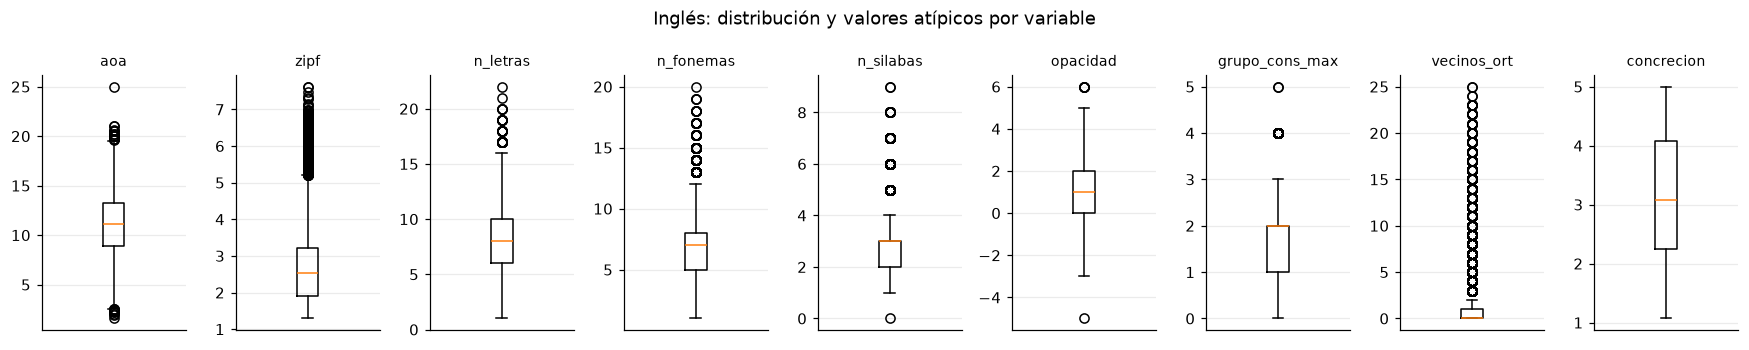

In [6]:
NUMS_EDA = ["aoa", "zipf", "n_letras", "n_fonemas", "n_silabas", "opacidad", "grupo_cons_max", "vecinos_ort", "concrecion"]
def limites_iqr(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); r = q3 - q1
    return q1 - k * r, q3 + k * r

filas = []
for v in NUMS_EDA:
    s = en[v].dropna(); lo, hi = limites_iqr(s); fuera = en.loc[(en[v] < lo) | (en[v] > hi)]
    filas.append({"variable": v, "mín": s.min(), "máx": s.max(), "límite inf": lo, "límite sup": hi,
                  "atípicos": len(fuera), "%": 100 * len(fuera) / len(s), "ejemplos": ", ".join(fuera["palabra"].head(4))})
atipicos = pd.DataFrame(filas).set_index("variable")
display(atipicos.round(2))

logicas = {
    "EN · 0 sílabas": en["n_silabas"] == 0,
    "EN · más sílabas que letras": en["n_silabas"] > en["n_letras"],
    "EN · más del doble de fonemas que letras": en["n_fonemas"] > 2 * en["n_letras"],
    "EN · AoA < 3 años (muy temprana)": en["aoa"] < 3,
    "EN · poco conocida (< 50 %)": en["pct_conocida"] < .5,
}
for n, m in logicas.items():
    print(f"{n:<45} {int(m.sum()):>6}  {', '.join(en.loc[m, 'palabra'].head(6))}")
print("\nES · categoría dudosa (revisión manual):", es_full.loc[es_full.palabra.isin(["vino", "poder", "ser"]), ["palabra", "categoria", "traduccion_en"]].to_dict("records"))

fig, axes = plt.subplots(1, len(NUMS_EDA), figsize=(16, 3.2))
for ax, v in zip(axes, NUMS_EDA):
    ax.boxplot(en[v].dropna()); ax.set_title(v, fontsize=9); ax.set_xticks([])
fig.suptitle("Inglés: distribución y valores atípicos por variable"); plt.tight_layout(); guardar(fig, "16_atipicos"); plt.show()

**Lectura y decisiones**

| Anomalía | Magnitud | Decisión y motivo |
|---|---|---|
| Atípicos en vecinos ortográficos (14,8 %) y sílabas (8,1 %) | Son colas largas, no errores: palabras cortas con muchos vecinos y palabras largas reales (*abbreviation*) | **Se mantienen** (ver §3.1) |
| Atípicos en AoA (0,1 %), letras, fonemas, opacidad | Palabras reales poco frecuentes | **Se mantienen** |
| `n_silabas = 0` (1 palabra, *frays*) | Error de la fuente | Se mantiene: 1 en 31.000 no altera el modelo; se documenta |
| Menos del 50 % conocía la palabra (2.278) | AoA calculada con pocos juicios | **Se excluyen** del entrenamiento |
| Categoría dudosa en español (*vino* = verbo) | Pocos casos | Se mantienen y se marcan como limitación |
| AoA < 3 años (43 palabras) | Extremo válido y escaso | Se mantienen; explica la dificultad del modelo en el nivel 1 |

### 2.5 Distribución del objetivo y relaciones principales

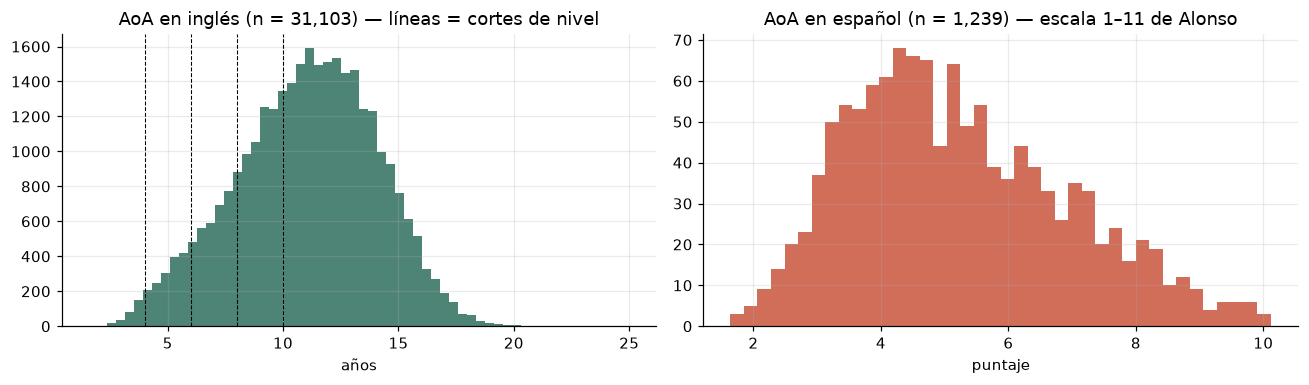

1 · Primeras palabras         319
2 · Preescolar               1669
3 · Lectura inicial          3323
4 · Lector en desarrollo     5762
Fuera de foco               20030


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(en["aoa"], bins=60, color=C1, alpha=.85)
for c in CORTES[1:-1]: axes[0].axvline(c, ls="--", c="k", lw=.7)
axes[0].set_title(f"AoA en inglés (n = {len(en):,}) — líneas = cortes de nivel"); axes[0].set_xlabel("años")
axes[1].hist(es_full["aoa"], bins=40, color=C2, alpha=.85)
axes[1].set_title(f"AoA en español (n = {len(es_full):,}) — escala 1–11 de Alonso"); axes[1].set_xlabel("puntaje")
plt.tight_layout(); guardar(fig, "01_distribucion_aoa"); plt.show()
print(pd.Series(nivel(en["aoa"])).map(dict(enumerate(NIVELES))).value_counts().reindex(NIVELES).to_string())

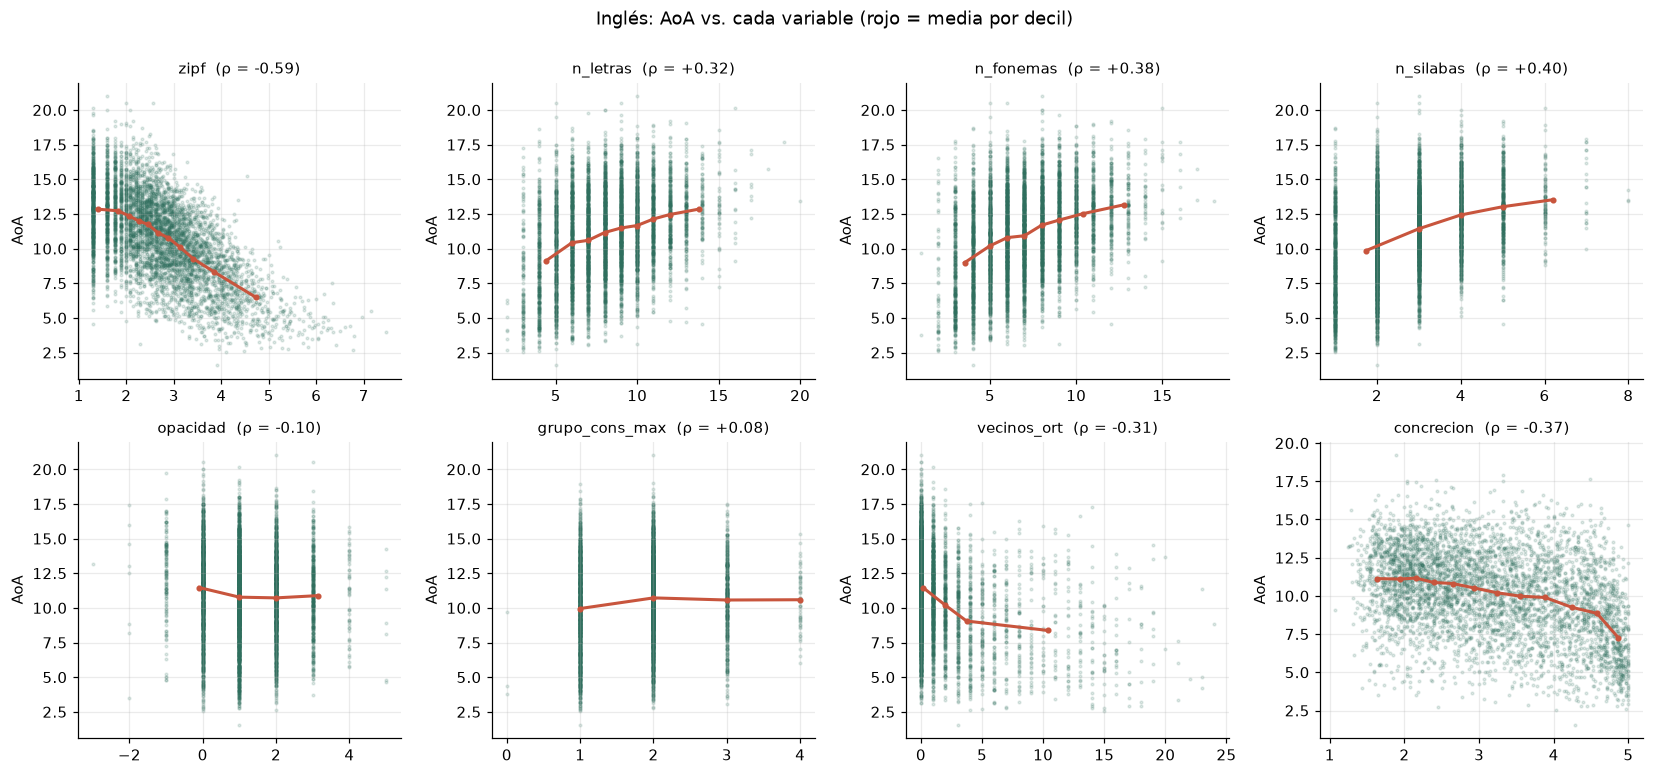

In [8]:
VARS_NUM = ["zipf", "n_letras", "n_fonemas", "n_silabas", "opacidad", "grupo_cons_max", "vecinos_ort", "concrecion"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
muestra = en.sample(6000, random_state=SEED)
for ax, v in zip(axes.ravel(), VARS_NUM):
    d = muestra[[v, "aoa"]].dropna()
    ax.scatter(d[v], d["aoa"], s=3, alpha=.15, color=C1)
    g = d.groupby(pd.qcut(d[v], 12, duplicates="drop"), observed=True).agg(x=(v, "mean"), y=("aoa", "mean"))
    ax.plot(g["x"], g["y"], color=C2, marker="o", ms=3, lw=2)
    rho = stats.spearmanr(en[v], en["aoa"], nan_policy="omit")[0]
    ax.set_title(f"{v}  (ρ = {rho:+.2f})", fontsize=10); ax.set_ylabel("AoA")
fig.suptitle("Inglés: AoA vs. cada variable (rojo = media por decil)", y=1.0)
plt.tight_layout(); guardar(fig, "02_relaciones_en"); plt.show()

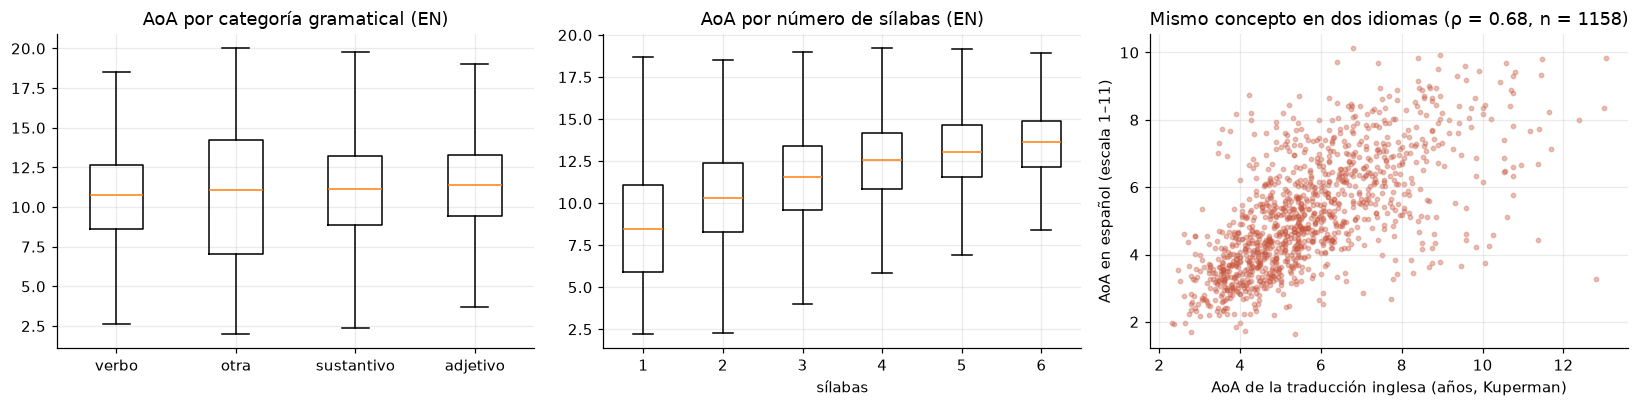

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
o = en.groupby("categoria")["aoa"].median().sort_values().index
axes[0].boxplot([en.loc[en.categoria == c, "aoa"] for c in o], tick_labels=o, showfliers=False)
axes[0].set_title("AoA por categoría gramatical (EN)")
s = en[en["n_silabas"] <= 6]
axes[1].boxplot([s.loc[s.n_silabas == k, "aoa"] for k in range(1, 7)], tick_labels=range(1, 7), showfliers=False)
axes[1].set_title("AoA por número de sílabas (EN)"); axes[1].set_xlabel("sílabas")
d = es_full.dropna(subset=["aoa_equivalente_en"])
axes[2].scatter(d["aoa_equivalente_en"], d["aoa"], s=8, alpha=.35, color=C2)
rho = stats.spearmanr(d["aoa_equivalente_en"], d["aoa"])[0]
axes[2].set_xlabel("AoA de la traducción inglesa (años, Kuperman)"); axes[2].set_ylabel("AoA en español (escala 1–11)")
axes[2].set_title(f"Mismo concepto en dos idiomas (ρ = {rho:.2f}, n = {len(d)})")
plt.tight_layout(); guardar(fig, "03_categoria_silabas_bilingue"); plt.show()

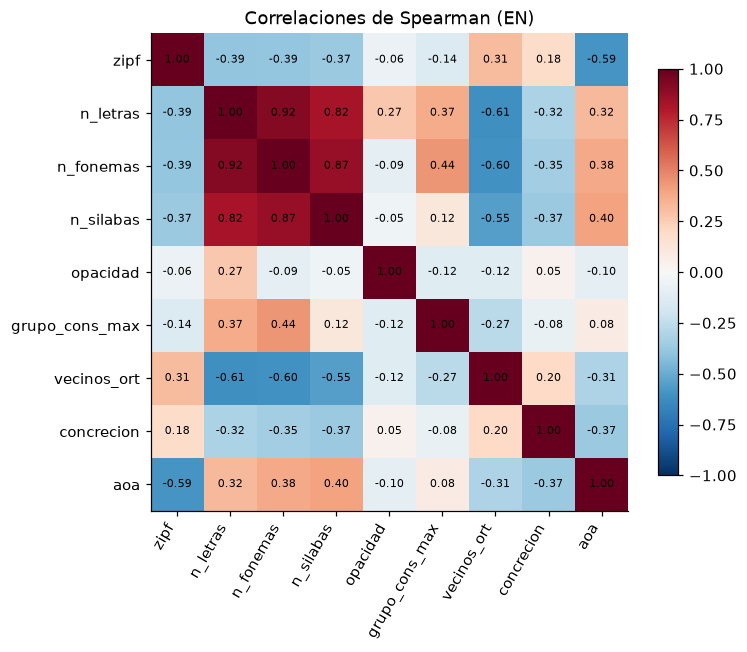

In [10]:
corr = en[VARS_NUM + ["aoa"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=.8); ax.set_title("Correlaciones de Spearman (EN)")
guardar(fig, "04_correlaciones"); plt.show()

**Hallazgos del EDA**
1. **La frecuencia es la variable más fuerte** (ρ ≈ −0,59): los niños aprenden primero lo que escuchan más. La relación no es lineal; se aplana en los extremos.
2. **Las palabras concretas se aprenden antes** (ρ ≈ −0,37): *perro* antes que *justicia*. Las palabras que se pueden dibujar son ideales para los primeros niveles.
3. **El largo y las sílabas aumentan la AoA** (ρ ≈ +0,3 a +0,4) y están **muy correlacionados entre sí** (letras–fonemas ρ ≈ 0,9). La regresión lineal necesita regularización por esta colinealidad.
4. **Muchos vecinos ortográficos → aprendizaje más temprano**: las palabras cortas y comunes (*cat, hat, bat*) forman "familias" y son la base del método de *word families* en inglés.
5. **Categoría:** a igual frecuencia, los **adjetivos** tienden a aprenderse más tarde que sustantivos y verbos; entre estos dos la diferencia es pequeña.
6. **El concepto se transfiere entre idiomas:** la AoA de un concepto en español y la de su traducción al inglés correlacionan ρ ≈ 0,68. Por eso tiene sentido intentar transferir el modelo.
7. **El objetivo es continuo y casi normal** (media ≈ 11 años). Solo ~17 % de las palabras está en los niveles infantiles (< 8 años) y apenas ~1 % en el nivel 1, así que hay que vigilar especialmente el error en ese tramo.

## 3. Preparación de los datos

* **Filtro de calidad:** solo palabras conocidas por al menos el 50 % de los evaluadores (AoA confiable).
* **Variables derivadas** (en `lexico.py`): Zipf, opacidad (letras − fonemas), grupo consonántico máximo, vecindario de Coltheart.
* **Split 80/20** estratificado por nivel de AoA, para que el test tenga la misma proporción de palabras infantiles. El test **no se toca** hasta la evaluación final.
* **`Pipeline`**: imputación con mediana más indicador de ausencia, escalado estándar y *one-hot* de la categoría. Todo se ajusta **dentro de cada fold**, así no hay fuga de información.

In [11]:
NUM = VARS_NUM
CAT = ["categoria"]
OBJ = "aoa"

en = en[en["pct_conocida"] >= .5].reset_index(drop=True)
X, y = en[NUM + CAT], en[OBJ]
estr = nivel(y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=estr, random_state=SEED)
pal_test = en.loc[X_test.index, "palabra"]
print(f"Train {X_train.shape} | Test {X_test.shape} | AoA media train {y_train.mean():.2f} / test {y_test.mean():.2f}")

def preprocesador(num=NUM, cat=CAT):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("esc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="otra")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat)])

def pipe(modelo, **kw):
    return Pipeline([("prep", preprocesador(**kw)), ("modelo", modelo)])

en.to_csv(DATA_PROC / "palabras_en_modelado.csv", index=False)
es_full.to_csv(DATA_PROC / "palabras_es_modelado.csv", index=False)

Train (23060, 9) | Test (5765, 9) | AoA media train 10.69 / test 10.73


### 3.1 ¿Hay que eliminar los atípicos? Prueba de sensibilidad

La decisión no se toma a ojo: se compara el error en validación entrenando **con** y **sin** las filas atípicas. El filtro se aplica solo al *train* de cada fold y la validación queda completa, porque en producción llegarán palabras largas o raras.

In [12]:
colas = ["n_letras", "n_fonemas", "n_silabas", "vecinos_ort", "zipf"]
res = {(m, f): [] for m in ("Ridge", "Gradient Boosting") for f in ("con atípicos", "sin atípicos")}
for tr, va in KFold(5, shuffle=True, random_state=SEED).split(X_train):
    Xa, ya = X_train.iloc[tr], y_train.iloc[tr]
    lim = {v: limites_iqr(Xa[v].dropna()) for v in colas}
    ok = np.logical_and.reduce([(Xa[v].between(*lim[v]) | Xa[v].isna()).to_numpy() for v in colas])
    for m, est in [("Ridge", Ridge()), ("Gradient Boosting", HistGradientBoostingRegressor(random_state=SEED))]:
        for f, mask in [("con atípicos", np.ones(len(Xa), bool)), ("sin atípicos", ok)]:
            mod = pipe(clone(est)).fit(Xa[mask], ya[mask])
            res[(m, f)].append(mean_absolute_error(y_train.iloc[va], mod.predict(X_train.iloc[va])))
sensibilidad = pd.Series({k: np.mean(v) for k, v in res.items()}).unstack()
print(f"Filas atípicas en el último fold de train: {(~ok).mean():.1%}")
sensibilidad.round(4)

Filas atípicas en el último fold de train: 23.8%


,con atípicos,sin atípicos
Gradient Boosting,1.4859,1.5126
Ridge,1.5821,1.6043


**Conclusión:** quitar las filas atípicas (23,8 % del train) **empeora** el error de validación en los dos modelos (Ridge 1,582 → 1,604; Gradient Boosting 1,486 → 1,513 años). Los atípicos contienen señal (palabras largas, raras o con muchos vecinos), así que **no se eliminan**.

## 4. Modelado

1. **Línea base:** `DummyRegressor`, que predice siempre la media.
2. **Dos modelos supervisados base:** **Ridge** (regresión lineal regularizada; interpretable y robusta a la colinealidad) y **Árbol de Decisión** (no lineal).
3. **Ensambles:** *Bagging* de árboles, **Random Forest** y **Gradient Boosting** (`HistGradientBoosting`). Después, **Voting** y **Stacking** sobre los mejores.
4. **Optimización de hiperparámetros** con validación cruzada de 5 folds sobre *train*. Se optimiza el **MAE** (error medio en años), que es fácil de explicar al equipo pedagógico.

### 4.0 Por qué estos algoritmos y esta configuración

| Algoritmo | Por qué es adecuado aquí | Configuración que se controla |
|---|---|---|
| **Ridge** | Línea de referencia interpretable; la penalización L2 estabiliza los coeficientes con variables colineales (letras–fonemas) | `alpha` (fuerza de la regularización) |
| **Árbol de decisión** | Capta no linealidades e interacciones sin escalar; sirve como base para medir cuánto aporta ensamblar | `max_depth`, `min_samples_leaf`, `criterion` |
| **Bagging / Random Forest** | Promedian árboles distintos para bajar la varianza; RF además sortea variables en cada corte | `n_estimators`, `max_features`, `max_samples`, profundidad |
| **Gradient Boosting (histogramas)** | Corrige errores en secuencia (baja el sesgo), es rápido con ~23.000 filas y admite *early stopping* | `learning_rate`, `max_iter`, `max_leaf_nodes`, L2 |
| **Voting / Stacking** | Combinan familias distintas (lineal + bagging + boosting) | modelos base y meta-modelo Ridge |

Se descartaron SVR (costo cuadrático con 23.000 filas y 6 modelos en CV repetida), k-NN (sensible a la escala y a variables redundantes, y lento al predecir en la app) y redes neuronales (pocas variables tabulares: no hay señal que justifique la complejidad).

In [13]:
cv5 = KFold(5, shuffle=True, random_state=SEED)
SCORING = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

def evaluar_cv(nombre, modelo, cv=cv5, Xt=None, yt=None):
    Xt = X_train if Xt is None else Xt; yt = y_train if yt is None else yt
    t0 = time.time()
    r = cross_validate(modelo, Xt, yt, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=-1)
    return {"modelo": nombre,
            "MAE val": -r["test_mae"].mean(), "MAE d.e.": r["test_mae"].std(), "RMSE val": -r["test_rmse"].mean(),
            "R² val": r["test_r2"].mean(), "MAE train": -r["train_mae"].mean(),
            "brecha MAE": -r["test_mae"].mean() + r["train_mae"].mean(), "seg": time.time() - t0}

resultados = []
default = {
    "Dummy (media)":        pipe(DummyRegressor()),
    "Ridge":                pipe(Ridge()),
    "Árbol de Decisión":    pipe(DecisionTreeRegressor(random_state=SEED)),
    "Bagging (árboles)":    pipe(BaggingRegressor(DecisionTreeRegressor(random_state=SEED), n_estimators=100, random_state=SEED, n_jobs=-1)),
    "Random Forest":        pipe(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting":    pipe(HistGradientBoostingRegressor(random_state=SEED)),
}
for n, m in default.items():
    resultados.append(evaluar_cv(n + " [default]", m))
pd.DataFrame(resultados).round(3)

,modelo,MAE val,MAE d.e.,RMSE val,R² val,MAE train,brecha MAE,seg
0,Dummy (media) [default],2.358,0.019,2.899,-0.000,2.358,0.000,1.689
1,Ridge [default],1.582,0.012,1.988,0.530,1.581,0.001,0.162
2,Árbol de Decisión [default],2.123,0.020,2.690,0.139,0.061,2.062,0.392
3,Bagging (árboles) [default],1.562,0.016,1.977,0.535,0.606,0.956,10.871
4,Random Forest [default],1.557,0.015,1.972,0.537,0.603,0.955,21.338
5,Gradient Boosting [default],1.486,0.014,1.882,0.579,1.420,0.066,0.902


**Con hiperparámetros por defecto:**
* El **árbol sin podar memoriza**: MAE de train ≈ 0 y validación muy peor que Ridge. Es alta varianza.
* **Bagging** promedia 100 árboles iguales a ese y baja mucho el error de validación. Es la primera evidencia del aporte de los ensambles: **reducen varianza**.
* **Gradient Boosting** ya supera a Ridge con sus valores por defecto, porque capta las no linealidades (la frecuencia se aplana en los extremos, interacción largo × frecuencia). El **Random Forest** por defecto apenas supera a Ridge y tiene una brecha enorme entre train y validación (≈ 0,95 años): sus árboles crecen hasta memorizar.

### 4.1 Optimización de hiperparámetros

| Modelo | Estrategia | Espacio | Justificación |
|---|---|---|---|
| Ridge | `GridSearchCV` | `alpha` ∈ 10⁻³…10³ (13 valores) | 1 hiperparámetro continuo: la grilla es exhaustiva y barata |
| Árbol | `RandomizedSearchCV` (40) | profundidad, hoja mínima, criterio | Controlar el sobreajuste |
| Random Forest | `RandomizedSearchCV` (15) | árboles, profundidad, hoja mínima, `max_features`, `max_samples` | 5 hiperparámetros: una grilla completa tendría cientos de combinaciones, y la búsqueda aleatoria explora el mismo espacio mucho más barato |
| Gradient Boosting | `RandomizedSearchCV` (35) | `learning_rate` (log-uniforme), hojas, profundidad, L2, `max_features`, iteraciones con *early stopping* | Los hiperparámetros interactúan entre sí; el *early stopping* evita fijar a mano el número de árboles |

In [14]:
busquedas = {}
def buscar(nombre, modelo, espacio, n_iter=None):
    t0 = time.time()
    if n_iter is None:
        s = GridSearchCV(pipe(modelo), espacio, cv=cv5, scoring="neg_mean_absolute_error", n_jobs=-1)
    else:
        s = RandomizedSearchCV(pipe(modelo), espacio, n_iter=n_iter, cv=cv5, scoring="neg_mean_absolute_error",
                               n_jobs=-1, random_state=SEED)
    s.fit(X_train, y_train)
    busquedas[nombre] = s
    print(f"{nombre:<20} mejor MAE CV = {-s.best_score_:.3f}  ({time.time()-t0:.0f}s)  ",
          {k.replace('modelo__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()})

buscar("Ridge", Ridge(), {"modelo__alpha": np.logspace(-3, 3, 13)})
buscar("Árbol de Decisión", DecisionTreeRegressor(random_state=SEED),
       {"modelo__max_depth": [4, 6, 8, 10, 12, 15, None], "modelo__min_samples_leaf": [5, 10, 20, 40, 80, 150],
        "modelo__criterion": ["squared_error", "absolute_error", "friedman_mse"]}, n_iter=40)
buscar("Random Forest", RandomForestRegressor(random_state=SEED, n_jobs=-1),
       {"modelo__n_estimators": [200, 400], "modelo__max_depth": [None, 12, 20],
        "modelo__min_samples_leaf": [1, 3, 5, 10, 20], "modelo__max_features": [0.33, 0.5, 0.7, 1.0],
        "modelo__max_samples": [0.5, 0.7, None]}, n_iter=15)
buscar("Gradient Boosting", HistGradientBoostingRegressor(random_state=SEED, early_stopping=True, validation_fraction=.1, n_iter_no_change=25),
       {"modelo__learning_rate": stats.loguniform(0.01, 0.3), "modelo__max_iter": [300, 600, 1200],
        "modelo__max_leaf_nodes": [15, 31, 63, 127], "modelo__max_depth": [None, 4, 6, 10],
        "modelo__min_samples_leaf": [10, 20, 50, 100], "modelo__l2_regularization": [0, 0.1, 1, 5, 10],
        "modelo__max_features": [0.5, 0.7, 1.0], "modelo__loss": ["squared_error", "absolute_error"]}, n_iter=35)

Ridge                mejor MAE CV = 1.582  (1s)   {'alpha': np.float64(0.001)}


Árbol de Decisión    mejor MAE CV = 1.529  (17s)   {'min_samples_leaf': 40, 'max_depth': 10, 'criterion': 'squared_error'}


Random Forest        mejor MAE CV = 1.488  (163s)   {'n_estimators': 400, 'min_samples_leaf': 5, 'max_samples': 0.7, 'max_features': 0.5, 'max_depth': 12}


Gradient Boosting    mejor MAE CV = 1.482  (66s)   {'l2_regularization': 0, 'learning_rate': np.float64(0.0178), 'loss': 'squared_error', 'max_depth': None, 'max_features': 0.5, 'max_iter': 1200, 'max_leaf_nodes': 31, 'min_samples_leaf': 20}


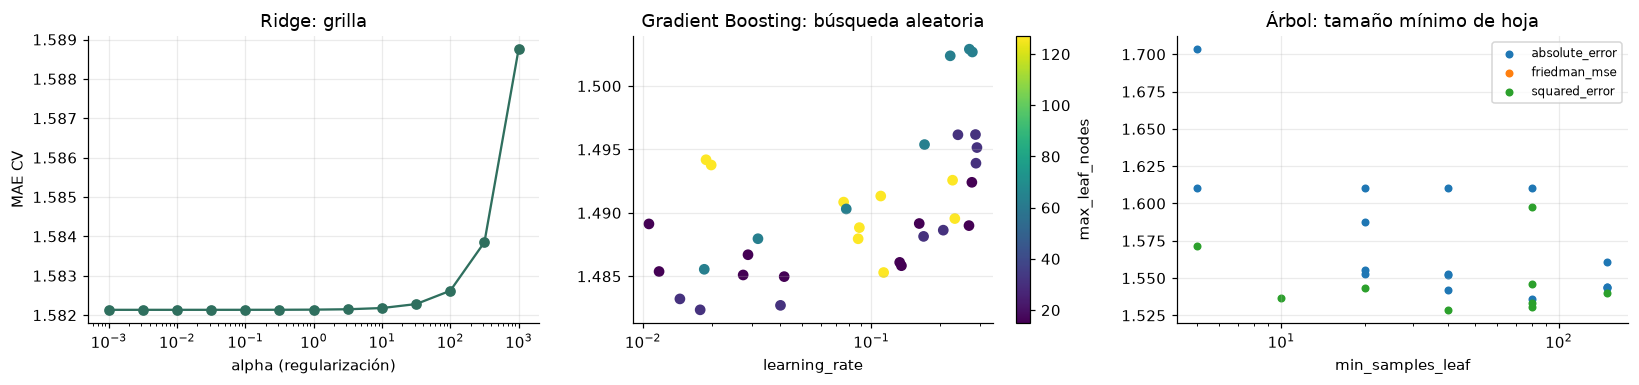

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
r = pd.DataFrame(busquedas["Ridge"].cv_results_)
axes[0].plot(r["param_modelo__alpha"].astype(float), -r["mean_test_score"], marker="o", color=C1)
axes[0].set_xscale("log"); axes[0].set_xlabel("alpha (regularización)"); axes[0].set_ylabel("MAE CV"); axes[0].set_title("Ridge: grilla")
r = pd.DataFrame(busquedas["Gradient Boosting"].cv_results_)
sc = axes[1].scatter(r["param_modelo__learning_rate"].astype(float), -r["mean_test_score"],
                     c=r["param_modelo__max_leaf_nodes"].astype(float), cmap="viridis")
axes[1].set_xscale("log"); axes[1].set_xlabel("learning_rate"); axes[1].set_title("Gradient Boosting: búsqueda aleatoria")
fig.colorbar(sc, ax=axes[1], label="max_leaf_nodes")
r = pd.DataFrame(busquedas["Árbol de Decisión"].cv_results_)
for crit, g in r.groupby("param_modelo__criterion"):
    g = g.sort_values("param_modelo__min_samples_leaf")
    axes[2].scatter(g["param_modelo__min_samples_leaf"].astype(float), -g["mean_test_score"], label=crit, s=18)
axes[2].set_xscale("log"); axes[2].set_xlabel("min_samples_leaf"); axes[2].set_title("Árbol: tamaño mínimo de hoja"); axes[2].legend(fontsize=8)
plt.tight_layout(); guardar(fig, "05_optimizacion_hiperparametros"); plt.show()

In [16]:
tuned = {n: s.best_estimator_ for n, s in busquedas.items()}
for n, m in tuned.items():
    resultados.append(evaluar_cv(n + " [optimizado]", m))
comp = pd.DataFrame(resultados).set_index("modelo")
tabla_mejora = pd.DataFrame([{
    "modelo": n,
    "MAE default": comp.loc[n + " [default]", "MAE val"], "MAE optimizado": comp.loc[n + " [optimizado]", "MAE val"],
    "Δ MAE (años)": comp.loc[n + " [optimizado]", "MAE val"] - comp.loc[n + " [default]", "MAE val"],
    "R² default": comp.loc[n + " [default]", "R² val"], "R² optimizado": comp.loc[n + " [optimizado]", "R² val"],
    "brecha default": comp.loc[n + " [default]", "brecha MAE"], "brecha optimizado": comp.loc[n + " [optimizado]", "brecha MAE"],
} for n in tuned]).round(3)
tabla_mejora

,modelo,MAE default,MAE optimizado,Δ MAE (años),R² default,R² optimizado,brecha default,brecha optimizado
0,Ridge,1.582,1.582,-0.000,0.530,0.530,0.001,0.001
1,Árbol de Decisión,2.123,1.529,-0.594,0.139,0.553,2.062,0.075
2,Random Forest,1.557,1.488,-0.069,0.537,0.578,0.955,0.157
3,Gradient Boosting,1.486,1.482,-0.004,0.579,0.581,0.066,0.059


**Qué logró la optimización**
* **Árbol:** limitar la profundidad y exigir hojas grandes elimina la memorización. Es la mayor mejora y la brecha casi desaparece.
* **Random Forest:** limitar la profundidad y la hoja mínima, y submuestrear filas (`max_samples`) y variables (`max_features`), reduce la brecha de ≈ 0,95 a ≈ 0,16 años y baja el MAE ~0,07 años.
* **Gradient Boosting:** la configuración por defecto ya era buena. La búsqueda encontró una tasa de aprendizaje más baja con más iteraciones y *early stopping*, que mejora el error solo levemente (milésimas de año). Es un resultado honesto: no todo modelo gana mucho con la optimización.
* **Ridge:** casi no cambia. El modelo lineal tiene **alto sesgo**, y ninguna regularización le permite representar la curvatura de la frecuencia. Es la justificación empírica para usar modelos no lineales.

### 4.2 Ensambles heterogéneos: Voting y Stacking

In [17]:
base = [("ridge", tuned["Ridge"]), ("rf", tuned["Random Forest"]), ("hgb", tuned["Gradient Boosting"])]
ensambles = {
    "Voting (Ridge+RF+HGB)":   VotingRegressor(base, n_jobs=-1),
    "Stacking (Ridge+RF+HGB)": StackingRegressor(base, final_estimator=Ridge(alpha=1.0), cv=KFold(5, shuffle=True, random_state=SEED), n_jobs=-1),
}
for n, m in ensambles.items():
    resultados.append(evaluar_cv(n, m))

oof = pd.DataFrame({n: cross_val_predict(m, X_train, y_train, cv=cv5, n_jobs=-1) for n, m in base})
print("Correlación de los ERRORES out-of-fold entre modelos base:")
print(oof.sub(y_train.values, axis=0).corr().round(3).to_string())
comp = pd.DataFrame(resultados).set_index("modelo")
comp.sort_values("MAE val").round(3)

Correlación de los ERRORES out-of-fold entre modelos base:
       ridge     rf    hgb
ridge  1.000  0.935  0.939
rf     0.935  1.000  0.993
hgb    0.939  0.993  1.000


,MAE val,MAE d.e.,RMSE val,R² val,MAE train,brecha MAE,seg
modelo,,,,,,,
Stacking (Ridge+RF+HGB),1.481,0.014,1.875,0.582,1.403,0.079,87.233
Gradient Boosting [optimizado],1.482,0.014,1.876,0.581,1.424,0.059,4.423
Gradient Boosting [default],1.486,0.014,1.882,0.579,1.420,0.066,0.902
Random Forest [optimizado],1.488,0.015,1.882,0.578,1.331,0.157,10.432
Voting (Ridge+RF+HGB),1.495,0.013,1.886,0.577,1.423,0.072,18.092
Árbol de Decisión [optimizado],1.529,0.015,1.938,0.553,1.454,0.075,0.272
Random Forest [default],1.557,0.015,1.972,0.537,0.603,0.955,21.338
Bagging (árboles) [default],1.562,0.016,1.977,0.535,0.606,0.956,10.871
Ridge [optimizado],1.582,0.012,1.988,0.530,1.581,0.001,0.179


**¿Por qué Voting y Stacking aportan poco aquí?** Los errores *out-of-fold* de RF y Gradient Boosting correlacionan ≈ 0,99: se equivocan en las mismas palabras. Un ensamble heterogéneo solo mejora si sus miembros cometen errores **distintos**. El error que queda viene sobre todo del **ruido de la norma** (estimaciones subjetivas) y de información que las variables no capturan, como el significado o el contexto de uso, y no de la elección del algoritmo.

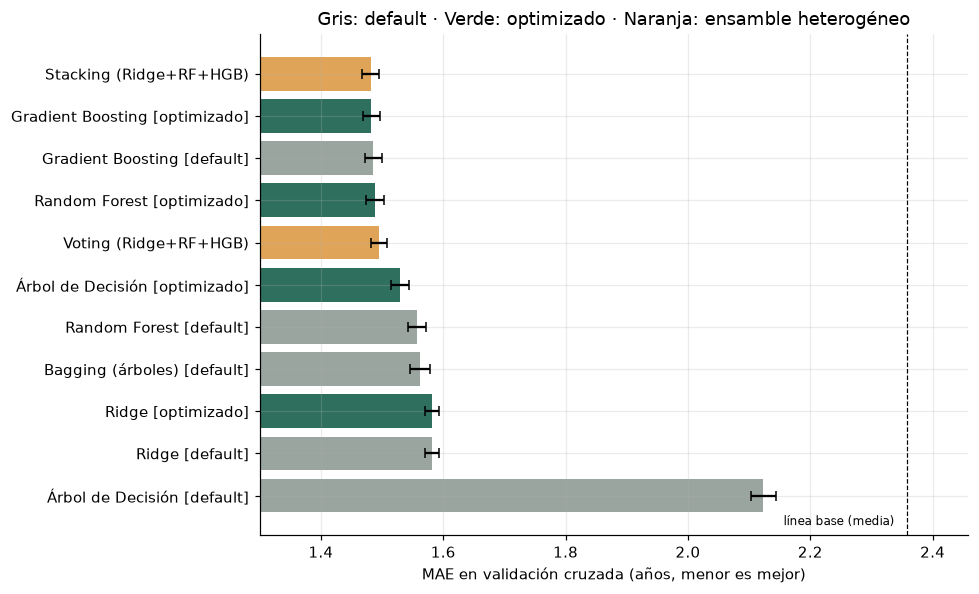

In [18]:
orden = comp.drop(index="Dummy (media) [default]").sort_values("MAE val", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
col = [C3 if ("Voting" in i or "Stacking" in i) else (C1 if "optimizado" in i else "#9aa5a0") for i in orden.index]
ax.barh(orden.index, orden["MAE val"], xerr=orden["MAE d.e."], color=col, capsize=3)
ax.axvline(comp.loc["Dummy (media) [default]", "MAE val"], ls="--", c="k", lw=.8)
ax.text(comp.loc["Dummy (media) [default]", "MAE val"] - .02, -.7, "línea base (media)", ha="right", fontsize=8)
ax.set_xlabel("MAE en validación cruzada (años, menor es mejor)")
ax.set_xlim(1.3, comp.loc["Dummy (media) [default]", "MAE val"] + .1)
ax.set_title("Gris: default · Verde: optimizado · Naranja: ensamble heterogéneo")
plt.tight_layout(); guardar(fig, "06_comparacion_modelos"); plt.show()

### 4.3 Cuánto aporta cada ensamble

In [19]:
v = lambda n: comp.loc[n, "MAE val"]
pares_ens = [("Bagging vs. un árbol", "Árbol de Decisión [default]", "Bagging (árboles) [default]"),
             ("Random Forest vs. árbol optimizado", "Árbol de Decisión [optimizado]", "Random Forest [optimizado]"),
             ("Gradient Boosting vs. árbol optimizado", "Árbol de Decisión [optimizado]", "Gradient Boosting [optimizado]"),
             ("Gradient Boosting vs. Ridge", "Ridge [optimizado]", "Gradient Boosting [optimizado]"),
             ("Voting vs. mejor modelo base", "Gradient Boosting [optimizado]", "Voting (Ridge+RF+HGB)"),
             ("Stacking vs. mejor modelo base", "Gradient Boosting [optimizado]", "Stacking (Ridge+RF+HGB)")]
aporte_ens = pd.DataFrame([{"comparación": c, "MAE referencia": v(a), "MAE ensamble": v(b), "mejora (años)": v(a) - v(b),
                            "mejora (%)": 100 * (v(a) - v(b)) / v(a)} for c, a, b in pares_ens]).set_index("comparación")
aporte_ens.round(4)

,MAE referencia,MAE ensamble,mejora (años),mejora (%)
comparación,,,,
Bagging vs. un árbol,2.1232,1.5617,0.5615,26.4469
Random Forest vs. árbol optimizado,1.5287,1.4880,0.0407,2.6616
Gradient Boosting vs. árbol optimizado,1.5287,1.4824,0.0464,3.0330
Gradient Boosting vs. Ridge,1.5821,1.4824,0.0998,6.3065
Voting vs. mejor modelo base,1.4824,1.4947,-0.0124,-0.8347
Stacking vs. mejor modelo base,1.4824,1.4811,0.0012,0.0816


**Aporte de los ensambles**
* **Bagging** reduce el MAE de un árbol sin podar en **0,56 años (26 %)**: es el mayor aporte y se debe a la reducción de varianza.
* **Random Forest** y **Gradient Boosting** mejoran al mejor árbol optimizado en ~0,04–0,05 años (3 %) y **Gradient Boosting** mejora a Ridge en **0,10 años (6 %)**.
* **Voting** empeora levemente al mejor modelo base (−0,012) y **Stacking** apenas lo mejora (+0,001): combinar modelos que fallan en las mismas palabras no ayuda.

## 5. Evaluación

### 5.1 Generalización: validación cruzada repetida y prueba estadística

Los finalistas se comparan con **validación cruzada repetida (5 folds × 3 repeticiones = 15 estimaciones por modelo)** y con el ***t*-test corregido de Nadeau y Bengio**. Este test es el adecuado para CV porque los folds comparten datos de entrenamiento y no son independientes.

In [20]:
rcv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
candidatos = {"Ridge": tuned["Ridge"], "Árbol de Decisión": tuned["Árbol de Decisión"],
              "Random Forest": tuned["Random Forest"], "Gradient Boosting": tuned["Gradient Boosting"],
              "Voting": ensambles["Voting (Ridge+RF+HGB)"], "Stacking": ensambles["Stacking (Ridge+RF+HGB)"]}
rep_scores = {}
for n, m in candidatos.items():
    rep_scores[n] = cross_validate(m, X_train, y_train, cv=rcv, scoring=SCORING, return_train_score=True, n_jobs=-1)
rep = pd.DataFrame({n: {"MAE media": -r["test_mae"].mean(), "MAE d.e.": r["test_mae"].std(),
                        "R² media": r["test_r2"].mean(), "MAE train": -r["train_mae"].mean(),
                        "brecha": -r["test_mae"].mean() + r["train_mae"].mean(),
                        "t. ajuste (s)": r["fit_time"].mean()} for n, r in rep_scores.items()}).T.sort_values("MAE media")
rep.round(3)

,MAE media,MAE d.e.,R² media,MAE train,brecha,t. ajuste (s)
Stacking,1.481,0.019,0.582,1.400,0.081,47.870
Gradient Boosting,1.482,0.018,0.581,1.420,0.062,2.149
Random Forest,1.488,0.020,0.578,1.332,0.157,6.418
Voting,1.495,0.018,0.577,1.422,0.073,8.572
Árbol de Decisión,1.531,0.021,0.552,1.453,0.078,0.107
Ridge,1.582,0.017,0.530,1.581,0.001,0.057


In [21]:
def ttest_corregido(a, b, n_train, n_test):
    d = np.asarray(a) - np.asarray(b); k = len(d)
    t = d.mean() / np.sqrt(d.var(ddof=1) * (1 / k + n_test / n_train))
    return d.mean(), t, 2 * stats.t.sf(abs(t), df=k - 1)

n_tr = int(len(X_train) * .8); n_te = len(X_train) - n_tr
mejor = rep.index[0]
pruebas = []
for n in rep.index[1:]:
    dm, t, p = ttest_corregido(-rep_scores[n]["test_mae"], -rep_scores[mejor]["test_mae"], n_tr, n_te)
    pruebas.append({"comparación": f"{n} − {mejor}", "Δ MAE (años)": dm, "t": t, "p-valor": p,
                    "significativa (α = 0,05)": "sí" if p < .05 else "no"})
pd.DataFrame(pruebas).round(4)

,comparación,Δ MAE (años),t,p-valor,"significativa (α = 0,05)"
0,Gradient Boosting − Stacking,0.0013,2.5030,0.0253,sí
1,Random Forest − Stacking,0.0070,4.9160,0.0002,sí
2,Voting − Stacking,0.0135,10.0708,0.0000,sí
3,Árbol de Decisión − Stacking,0.0500,13.6768,0.0000,sí
4,Ridge − Stacking,0.1009,20.6635,0.0000,sí


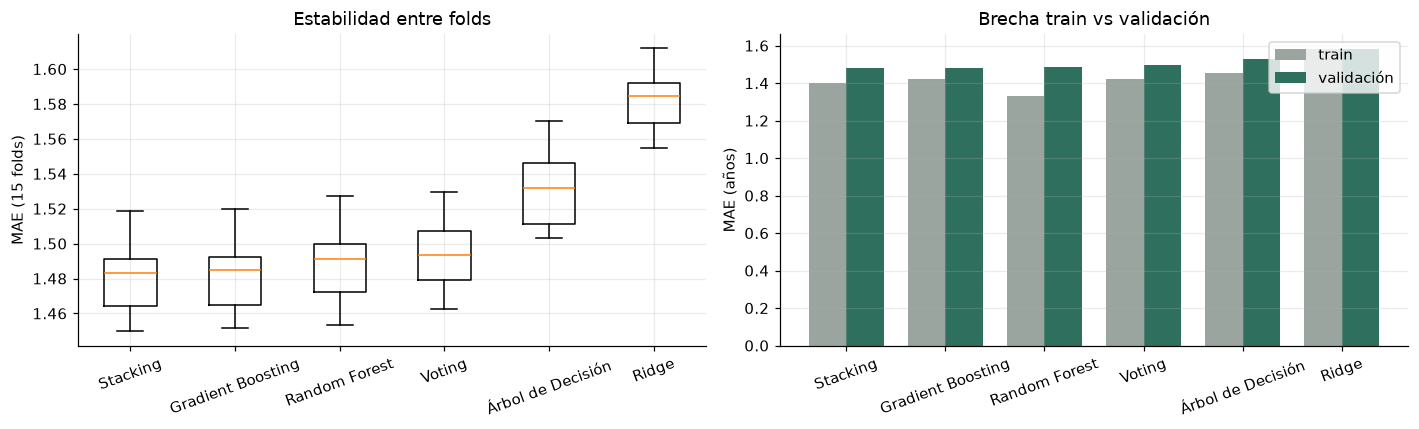

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
nombres = list(rep.index)
axes[0].boxplot([-rep_scores[n]["test_mae"] for n in nombres], tick_labels=nombres)
axes[0].set_ylabel("MAE (15 folds)"); axes[0].set_title("Estabilidad entre folds"); axes[0].tick_params(axis="x", rotation=20)
x = np.arange(len(nombres)); w = .38
axes[1].bar(x - w/2, [rep.loc[n, "MAE train"] for n in nombres], w, color="#9aa5a0", label="train")
axes[1].bar(x + w/2, [rep.loc[n, "MAE media"] for n in nombres], w, color=C1, label="validación")
axes[1].set_xticks(x); axes[1].set_xticklabels(nombres, rotation=20); axes[1].set_ylabel("MAE (años)")
axes[1].set_title("Brecha train vs validación"); axes[1].legend()
plt.tight_layout(); guardar(fig, "07_generalizacion_cv_repetida"); plt.show()

### 5.2 Selección de la solución

**Regla definida antes de mirar el test:**
1. Se parte del menor MAE medio en la CV repetida.
2. **Equivalencia práctica:** si un modelo más simple o más barato está a menos de **0,02 años (≈ 1 semana)** del mejor, se elige ese aunque la diferencia sea "estadísticamente significativa". Con 23.000 palabras, el *t*-test detecta diferencias irrelevantes para el negocio: significancia no es relevancia.
3. La brecha train–validación debe ser ≤ 0,30 años (KPI de generalización).

In [23]:
complejidad = {"Ridge": 1, "Árbol de Decisión": 1, "Gradient Boosting": 2, "Random Forest": 2, "Voting": 3, "Stacking": 4}
equivalentes = rep[(rep["MAE media"] - rep.loc[mejor, "MAE media"] < .02) & (rep["brecha"] <= .30)].copy()
equivalentes["complejidad"] = equivalentes.index.map(complejidad)
elegido = equivalentes.sort_values(["complejidad", "MAE media"]).index[0]
print("Modelos prácticamente equivalentes al mejor (< 0,02 años):")
print(equivalentes[["MAE media", "brecha", "t. ajuste (s)", "complejidad"]].round(3).to_string())
if rep.loc[elegido, "brecha"] > .30:
    aptos = rep[rep["brecha"] <= .30]
    elegido = aptos.index[0]
print(f"Mejor en CV: {mejor} | Modelo elegido: {elegido} (brecha {rep.loc[elegido, 'brecha']:.3f} años)")
modelo_final = clone(candidatos[elegido])

Modelos prácticamente equivalentes al mejor (< 0,02 años):
                   MAE media  brecha  t. ajuste (s)  complejidad
Stacking               1.481   0.081         47.870            4
Gradient Boosting      1.482   0.062          2.149            2
Random Forest          1.488   0.157          6.418            2
Voting                 1.495   0.073          8.572            3
Mejor en CV: Stacking | Modelo elegido: Gradient Boosting (brecha 0.062 años)


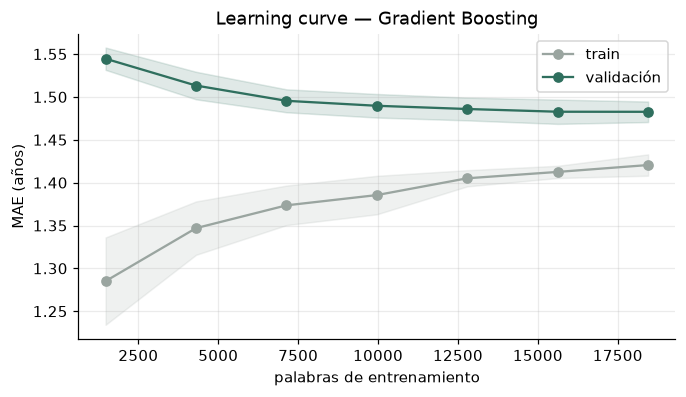

In [24]:
tam, tr, va = learning_curve(clone(modelo_final), X_train, y_train, cv=cv5, scoring="neg_mean_absolute_error",
                             train_sizes=np.linspace(.08, 1, 7), n_jobs=-1, shuffle=True, random_state=SEED)
fig, ax = plt.subplots(figsize=(7, 3.6))
for s, c, l in [(-tr, "#9aa5a0", "train"), (-va, C1, "validación")]:
    ax.plot(tam, s.mean(1), marker="o", c=c, label=l); ax.fill_between(tam, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=.15)
ax.set_xlabel("palabras de entrenamiento"); ax.set_ylabel("MAE (años)"); ax.set_title(f"Learning curve — {elegido}"); ax.legend()
guardar(fig, "08_learning_curve"); plt.show()

### 5.3 Evaluación final en test (palabras nunca vistas)

In [25]:
finales = {"Ridge": tuned["Ridge"], "Random Forest": tuned["Random Forest"], "Gradient Boosting": tuned["Gradient Boosting"],
           "Stacking": ensambles["Stacking (Ridge+RF+HGB)"]}
finales[elegido] = modelo_final
pred_test = {}
for n, m in finales.items():
    m.fit(X_train, y_train); pred_test[n] = m.predict(X_test)

def boot_ci(y, p, f, B=1000):
    rng = np.random.default_rng(SEED); y = np.asarray(y)
    v = [f(y[i], p[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(B))]
    return np.percentile(v, [2.5, 97.5])

def metricas_negocio(y, p):
    nv_r, nv_p = nivel(y), nivel(p)
    return {"exacto": np.mean(nv_r == nv_p), "±1 nivel": np.mean(np.abs(nv_r - nv_p) <= 1),
            "error grave": np.mean((np.asarray(y) >= 10) & (np.asarray(p) < 6))}

filas = []
for n, p in pred_test.items():
    lo, hi = boot_ci(y_test, p, mean_absolute_error); mn = metricas_negocio(y_test, p)
    filas.append({"modelo": n, "MAE test": mean_absolute_error(y_test, p), "IC95% MAE": f"[{lo:.3f}, {hi:.3f}]",
                  "RMSE": mean_squared_error(y_test, p) ** .5, "R²": r2_score(y_test, p),
                  "Spearman": stats.spearmanr(y_test, p)[0], "nivel exacto": mn["exacto"],
                  "nivel ±1": mn["±1 nivel"], "error grave": mn["error grave"],
                  "MAE CV": rep.loc[n, "MAE media"] if n in rep.index else np.nan})
test_tab = pd.DataFrame(filas).set_index("modelo").round(4)
test_tab

,MAE test,IC95% MAE,RMSE,R²,Spearman,nivel exacto,nivel ±1,error grave,MAE CV
modelo,,,,,,,,,
Ridge,1.6089,"[1.579, 1.640]",2.0147,0.5260,0.7055,0.6460,0.9443,0.0002,1.5820
Random Forest,1.5105,"[1.481, 1.539]",1.9030,0.5771,0.7350,0.6739,0.9447,0.0002,1.4882
Gradient Boosting,1.5014,"[1.472, 1.531]",1.8954,0.5805,0.7371,0.6742,0.9435,0.0005,1.4825
Stacking,1.5014,"[1.472, 1.531]",1.8950,0.5807,0.7371,0.6732,0.9447,0.0005,1.4812


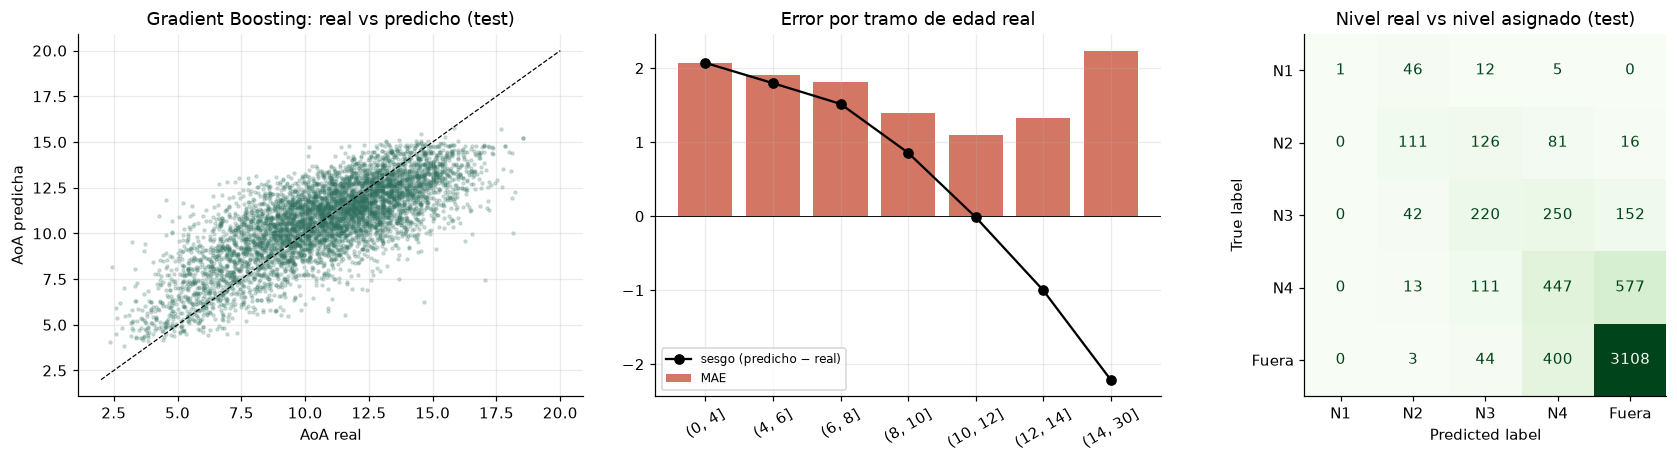

In [26]:
p = pred_test[elegido]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].scatter(y_test, p, s=4, alpha=.2, color=C1); axes[0].plot([2, 20], [2, 20], "k--", lw=.8)
axes[0].set_xlabel("AoA real"); axes[0].set_ylabel("AoA predicha"); axes[0].set_title(f"{elegido}: real vs predicho (test)")
banda = pd.cut(y_test, [0, 4, 6, 8, 10, 12, 14, 30])
err = pd.DataFrame({"banda": banda, "error": p - y_test}).groupby("banda", observed=True)["error"]
axes[1].bar(range(len(err)), err.apply(lambda e: e.abs().mean()), color=C2, alpha=.8, label="MAE")
axes[1].plot(range(len(err)), err.mean(), "ko-", label="sesgo (predicho − real)")
axes[1].axhline(0, c="k", lw=.6); axes[1].set_xticks(range(len(err))); axes[1].set_xticklabels([str(i) for i in err.mean().index], rotation=30)
axes[1].set_title("Error por tramo de edad real"); axes[1].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(nivel(y_test), nivel(p), labels=range(5)),
                       display_labels=["N1", "N2", "N3", "N4", "Fuera"]).plot(ax=axes[2], cmap="Greens", colorbar=False)
axes[2].set_title("Nivel real vs nivel asignado (test)"); axes[2].grid(False)
plt.tight_layout(); guardar(fig, "09_evaluacion_test"); plt.show()

**Lectura del error por tramo:** el modelo **sobreestima** la AoA de las palabras más tempranas y **subestima** la de las más tardías. Es la *regresión hacia la media* típica de cualquier regresor con ruido. Para el negocio, el sesgo va en la dirección segura: una palabra infantil puede quedar un nivel más arriba (se enseña un poco después), pero rara vez una palabra adulta cae en un nivel infantil (el KPI de error grave).

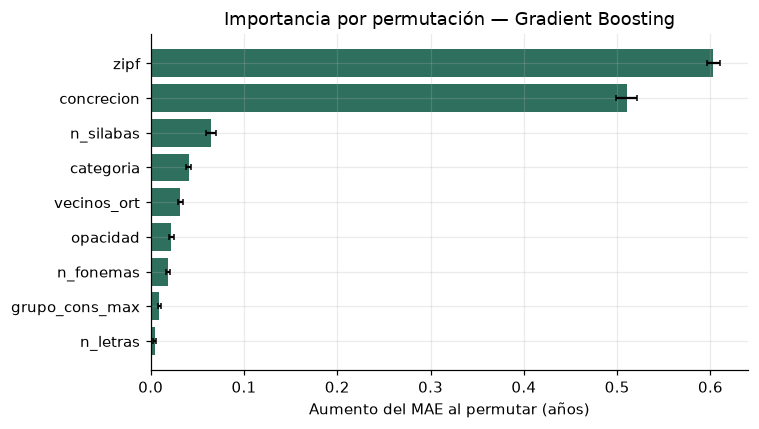

Mayores errores (para revisión pedagógica):


,palabra,AoA real,AoA predicha,error
735,meth,17.1,7.5,-9.6
1873,cellphone,14.7,6.2,-8.5
5417,twitter,18.1,10.0,-8.1
871,tickly,4.5,11.9,7.4
4940,boohoo,4.3,11.0,6.7
3163,chardonnay,16.2,9.6,-6.6
4413,blog,16.6,10.0,-6.6
2416,storytelling,5.2,11.7,6.5


Las palabras más tempranas del test (efecto de regresión a la media):


,palabra,AoA real,AoA predicha,error
5383,ouch,2.4,8.1,5.7
1122,water,2.4,4.1,1.7
433,grandma,2.6,5.9,3.3
2440,dad,2.6,4.5,1.9
3107,count,2.6,5.4,2.8
2767,carrot,2.7,6.2,3.5
288,jump,2.8,4.8,2.0
4794,animal,2.9,7.0,4.1
3131,sock,2.9,5.5,2.6
5526,bed,2.9,3.9,1.0


In [27]:
pi = permutation_importance(finales[elegido], X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=8, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"variable": X_test.columns, "importancia": pi.importances_mean, "d.e.": pi.importances_std}).sort_values("importancia")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp["variable"], imp["importancia"], xerr=imp["d.e."], color=C1, capsize=2)
ax.set_xlabel("Aumento del MAE al permutar (años)"); ax.set_title(f"Importancia por permutación — {elegido}")
plt.tight_layout(); guardar(fig, "10_importancia"); plt.show()

ej = pd.DataFrame({"palabra": pal_test.values, "AoA real": y_test.values, "AoA predicha": p}).round(1)
ej["error"] = (ej["AoA predicha"] - ej["AoA real"]).round(1)
print("Mayores errores (para revisión pedagógica):")
display(ej.reindex(ej["error"].abs().sort_values(ascending=False).index).head(8))
print("Las palabras más tempranas del test (efecto de regresión a la media):")
ej[(ej["AoA real"] < 6)].sort_values("AoA real").head(10)

### 5.4 Matriz de selección frente a los objetivos del negocio

In [28]:
interpret = {"Ridge": "alta (coeficientes)", "Random Forest": "media (importancias)", "Gradient Boosting": "media (importancias)", "Stacking": "baja (4 modelos)"}
matriz_sel = pd.DataFrame({n: {
    "MAE test ≤ 1,6": f"{test_tab.loc[n, 'MAE test']:.3f}", "R² ≥ 0,55": f"{test_tab.loc[n, 'R²']:.3f}",
    "Nivel ±1 ≥ 90 %": f"{test_tab.loc[n, 'nivel ±1']:.1%}", "Error grave ≤ 2 %": f"{test_tab.loc[n, 'error grave']:.2%}",
    "Brecha ≤ 0,30": f"{rep.loc[n, 'brecha']:.3f}", "Ajuste (s)": f"{rep.loc[n, 't. ajuste (s)']:.1f}",
    "Tamaño (MB)": f"{len(__import__('pickle').dumps(finales[n])) / 1e6:.1f}", "Interpretabilidad": interpret[n]} for n in interpret})
matriz_sel

,Ridge,Random Forest,Gradient Boosting,Stacking
"MAE test ≤ 1,6",1.609,1.510,1.501,1.501
"R² ≥ 0,55",0.526,0.577,0.581,0.581
Nivel ±1 ≥ 90 %,94.4%,94.5%,94.3%,94.5%
Error grave ≤ 2 %,0.02%,0.02%,0.05%,0.05%
"Brecha ≤ 0,30",0.001,0.157,0.062,0.081
Ajuste (s),0.1,6.4,2.1,47.9
Tamaño (MB),0.0,50.7,1.2,103.9
Interpretabilidad,alta (coeficientes),media (importancias),media (importancias),baja (4 modelos)


**Lectura:** los cuatro cumplen los KPIs de negocio. Gradient Boosting y Stacking empatan en error de test, pero Gradient Boosting pesa **1,2 MB** frente a **104 MB** y se ajusta ~24 veces más rápido. Para una app que debe funcionar sin conexión y re-entrenarse con datos nuevos, es la mejor opción. Ridge es el más simple, pero no cumple MAE ≤ 1,6.

## 6. Transferencia al español

Pino es *Spanish-first*, pero las normas en español son pocas (1.239 palabras con concepto vinculado). Se evalúan tres estrategias, todas con validación cruzada repetida sobre las palabras españolas:

| Estrategia | Descripción |
|---|---|
| **A · Transferencia directa** (*zero-shot*) | Se aplica el modelo inglés tal cual a las variables del español. No usa ningún dato de AoA español. |
| **B · Modelo propio** | Ridge / RF / Gradient Boosting entrenados solo con las 1.239 palabras españolas. |
| **C · Modelo propio + conocimiento transferido** | B más dos variables: la AoA del equivalente inglés (Kuperman) y la predicción del modelo inglés. Es un **stacking entre idiomas**. |

Como la escala española (1–11) difiere de la inglesa (años), en la estrategia A se mide la **correlación de Spearman** (orden), que no depende de la escala.

### 6.1 Optimización de hiperparámetros en español (validación cruzada anidada)

Con 1.239 palabras es fácil sobreajustar y también engañarse al optimizar. Por eso la búsqueda de hiperparámetros va **dentro** de cada fold: el CV interno (3 folds) elige la configuración y el CV externo (5 × 5) mide el error sobre palabras que la búsqueda no vio.

In [29]:
es = es_full.copy()
modelo_en = finales[elegido]
es["pred_modelo_en"] = modelo_en.predict(es[NUM + CAT])
rho_A = stats.spearmanr(es["pred_modelo_en"], es["aoa"])[0]
rho_eq = stats.spearmanr(es["aoa_equivalente_en"], es["aoa"], nan_policy="omit")[0]
print(f"A · Transferencia directa: Spearman = {rho_A:.3f}  (meta ≥ 0,60)")
print(f"   (referencia: AoA real de la traducción inglesa, ρ = {rho_eq:.3f})")

NUM_ES = NUM + ["complejidad_silabica"]
NUM_ES_C = NUM_ES + ["aoa_equivalente_en", "pred_modelo_en"]
rcv_es = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
inner = KFold(3, shuffle=True, random_state=SEED)

def ridge_es():
    return GridSearchCV(Pipeline([("e", StandardScaler()), ("r", Ridge())]), {"r__alpha": np.logspace(-2, 3, 11)},
                        cv=inner, scoring="neg_mean_absolute_error")
def rf_es():
    return RandomizedSearchCV(RandomForestRegressor(n_estimators=200, random_state=SEED),
        {"max_depth": [None, 6, 10], "min_samples_leaf": [1, 3, 5, 10, 20], "max_features": [.33, .5, .7, 1.0],
         "max_samples": [.5, .7, None]}, n_iter=8, cv=inner, scoring="neg_mean_absolute_error", random_state=SEED)
def hgb_es():
    return RandomizedSearchCV(HistGradientBoostingRegressor(random_state=SEED),
        {"learning_rate": stats.loguniform(.01, .2), "max_iter": [100, 200, 400], "max_leaf_nodes": [7, 15, 31],
         "min_samples_leaf": [10, 20, 40], "l2_regularization": [0, .1, 1, 5]},
        n_iter=8, cv=inner, scoring="neg_mean_absolute_error", random_state=SEED)
def stacking_es():
    return StackingRegressor([("ridge", ridge_es()), ("rf", rf_es()), ("hgb", hgb_es())], final_estimator=Ridge(alpha=1.0), cv=5)

def armar(modelo, num):
    return Pipeline([("prep", preprocesador(num=num)), ("modelo", modelo)])

def cv_es(nombre, modelo, num):
    m = armar(modelo, num)
    r = cross_validate(m, es[num + CAT], es["aoa"], cv=rcv_es, scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
                       return_train_score=True, n_jobs=-1)
    oofp = cross_val_predict(m, es[num + CAT], es["aoa"], cv=cv5, n_jobs=-1)
    return {"estrategia": nombre, "MAE": -r["test_mae"].mean(), "MAE d.e.": r["test_mae"].std(), "R²": r["test_r2"].mean(),
            "Spearman": stats.spearmanr(oofp, es["aoa"])[0], "RMSE": mean_squared_error(es["aoa"], oofp) ** .5,
            "brecha MAE": -r["test_mae"].mean() + r["train_mae"].mean()}, r

modelos_es = {
    "B · Ridge": (ridge_es, NUM_ES), "B · Random Forest": (rf_es, NUM_ES), "B · Gradient Boosting": (hgb_es, NUM_ES),
    "C · Ridge + transferencia": (ridge_es, NUM_ES_C), "C · RF + transferencia": (rf_es, NUM_ES_C),
    "C · HGB + transferencia": (hgb_es, NUM_ES_C), "C · Stacking + transferencia": (stacking_es, NUM_ES_C)}

res_es, raw_es = [], {}
dummy = cross_validate(armar(DummyRegressor(), NUM_ES), es[NUM_ES + CAT], es["aoa"], cv=rcv_es, scoring="neg_mean_absolute_error")
res_es.append({"estrategia": "Línea base (media)", "MAE": -dummy["test_score"].mean(), "MAE d.e.": dummy["test_score"].std(), "R²": 0})
t0 = time.time()
for nombre, (fabrica, num) in modelos_es.items():
    f, r = cv_es(nombre, fabrica(), num); res_es.append(f); raw_es[nombre] = r
tabla_es = pd.DataFrame(res_es).set_index("estrategia")
tabla_es.loc["A · Transferencia directa (zero-shot)", "Spearman"] = rho_A
print(f"CV anidada en {time.time() - t0:.0f} s")
tabla_es.round(3)

A · Transferencia directa: Spearman = 0.532  (meta ≥ 0,60)
   (referencia: AoA real de la traducción inglesa, ρ = 0.680)


CV anidada en 983 s


,MAE,MAE d.e.,R²,Spearman,RMSE,brecha MAE
estrategia,,,,,,
Línea base (media),1.404,0.065,0.000,NaN,NaN,NaN
B · Ridge,1.149,0.059,0.296,0.550,1.429,0.018
B · Random Forest,1.172,0.060,0.275,0.525,1.453,0.229
B · Gradient Boosting,1.159,0.058,0.287,0.542,1.436,0.132
C · Ridge + transferencia,0.964,0.054,0.469,0.703,1.238,0.017
C · RF + transferencia,0.967,0.051,0.475,0.704,1.227,0.222
C · HGB + transferencia,0.971,0.055,0.472,0.699,1.232,0.147
C · Stacking + transferencia,0.953,0.054,0.486,0.709,1.216,0.114
A · Transferencia directa (zero-shot),NaN,NaN,NaN,0.532,NaN,NaN


In [30]:
# Mismos modelos con hiperparámetros por defecto, para medir cuánto aporta optimizar en español
defaults_es = {"Ridge": Pipeline([("e", StandardScaler()), ("r", Ridge())]),
               "Random Forest": RandomForestRegressor(n_estimators=100, random_state=SEED),
               "Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED)}
filas = []
for etiqueta, num, nombres in [("B (solo español)", NUM_ES, ["B · Ridge", "B · Random Forest", "B · Gradient Boosting"]),
                               ("C (con transferencia)", NUM_ES_C, ["C · Ridge + transferencia", "C · RF + transferencia", "C · HGB + transferencia"])]:
    for (alg, est), n in zip(defaults_es.items(), nombres):
        f, r = cv_es(alg, est, num)
        dm, t, pval = ttest_corregido(-r["test_mae"], -raw_es[n]["test_mae"], int(len(es) * .8), len(es) - int(len(es) * .8))
        filas.append({"variables": etiqueta, "modelo": alg, "MAE default": f["MAE"], "MAE optimizado": tabla_es.loc[n, "MAE"],
                      "mejora": dm, "p-valor": pval, "brecha default": f["brecha MAE"], "brecha optimizado": tabla_es.loc[n, "brecha MAE"]})
opt_es = pd.DataFrame(filas).set_index(["variables", "modelo"])
opt_es.round(4)

MAE default  MAE optimizado  mejora  \
variables             modelo                                                   
B (solo español)      Ridge                   1.1490          1.1491 -0.0001   
                      Random Forest           1.2066          1.1721  0.0344   
                      Gradient Boosting       1.2631          1.1586  0.1045   
C (con transferencia) Ridge                   0.9638          0.9640 -0.0002   
                      Random Forest           0.9779          0.9673  0.0106   
                      Gradient Boosting       1.0227          0.9707  0.0521   

                                         p-valor  brecha default  \
variables             modelo                                       
B (solo español)      Ridge               0.7279          0.0175   
                      Random Forest       0.0083          0.7588   
                      Gradient Boosting   0.0000          0.6276   
C (con transferencia) Ridge               0.7289          0.0174   
                      Random Forest       0.3126          0.6158   
                      Gradient Boosting   0.0002          0.5908   

                                         brecha optimizado  
variables             modelo                                
B (solo español)      Ridge                         0.0176  
                      Random Forest                 0.2292  
                      Gradient Boosting             0.1323  
C (con transferencia) Ridge                         0.0172  
                      Random Forest                 0.2222  
                      Gradient Boosting             0.1469

**Efecto de optimizar en español**
* **Gradient Boosting** gana más: −0,10 años de escala sin transferencia y −0,05 con transferencia (p < 0,001); la brecha train–validación cae de ~0,6 a ~0,13–0,15.
* **Random Forest:** mejora significativa sin transferencia (−0,03, p < 0,01), no significativa con transferencia; la brecha cae de 0,6–0,76 a ~0,22.
* **Ridge:** no cambia. Con pocos datos y relaciones casi lineales ya estaba bien regularizado.
* La optimización **controla el sobreajuste**, pero lo que más mejora el error es **agregar el conocimiento del inglés** (−0,2).

Mejor estrategia ES: C · Stacking + transferencia
Ganancia de transferir conocimiento del inglés: B · Ridge → C · Stacking + transferencia: ΔMAE = -0.196 (p = 0.0000)


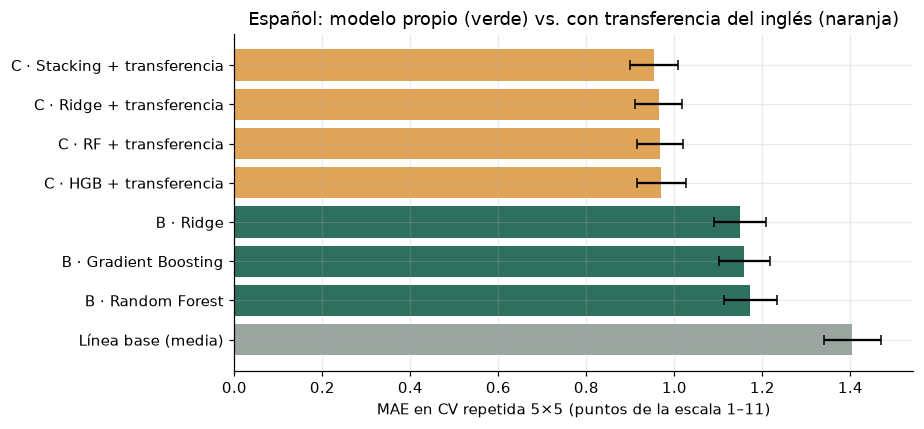

Hiperparámetros del modelo español final: {'ridge': {'alpha': 0.01}, 'rf': {'min_samples_leaf': 1, 'max_samples': None, 'max_features': 0.7, 'max_depth': 6}, 'hgb': {'l2_regularization': 1, 'learning_rate': 0.0257, 'max_iter': 200, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}}


In [31]:
mejor_es = tabla_es.drop(index=["Línea base (media)", "A · Transferencia directa (zero-shot)"]).sort_values("MAE").index[0]
b_mejor = tabla_es.filter(like="B ·", axis=0).sort_values("MAE").index[0]
dm, t, pval = ttest_corregido(-raw_es[b_mejor]["test_mae"], -raw_es[mejor_es]["test_mae"], int(len(es) * .8), len(es) - int(len(es) * .8))
print(f"Mejor estrategia ES: {mejor_es}")
print(f"Ganancia de transferir conocimiento del inglés: {b_mejor} → {mejor_es}: ΔMAE = {-dm:+.3f} (p = {pval:.4f})")

fig, ax = plt.subplots(figsize=(8.5, 4))
t = tabla_es.drop(index="A · Transferencia directa (zero-shot)").sort_values("MAE", ascending=False)
ax.barh(t.index, t["MAE"], xerr=t["MAE d.e."], color=[C3 if "C ·" in i else (C1 if "B ·" in i else "#9aa5a0") for i in t.index], capsize=3)
ax.set_xlabel("MAE en CV repetida 5×5 (puntos de la escala 1–11)"); ax.set_title("Español: modelo propio (verde) vs. con transferencia del inglés (naranja)")
plt.tight_layout(); guardar(fig, "11_transferencia_es"); plt.show()

fabrica, num_es_final = modelos_es[mejor_es]
modelo_es = armar(fabrica(), num_es_final).fit(es[num_es_final + CAT], es["aoa"])

def hiperparametros_es(m):
    m = m.named_steps["modelo"]
    sub = m.named_estimators_ if hasattr(m, "named_estimators_") else {"modelo": m}
    return {n: {k.replace("r__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                for k, v in s.best_params_.items()} for n, s in sub.items() if hasattr(s, "best_params_")}
hp_es = hiperparametros_es(modelo_es)
print("Hiperparámetros del modelo español final:", hp_es)

**Escala española → años (enlace equipercentil).** Para asignar **niveles de edad** en español hace falta expresar la escala 1–11 en años. Se usa *equating* equipercentil sobre los conceptos que tienen norma en ambos idiomas: a la palabra española en el percentil *q* de dificultad se le asigna la AoA en años del percentil *q* de sus traducciones inglesas. Esto conserva el orden del español y usa la escala en años de la norma inglesa.

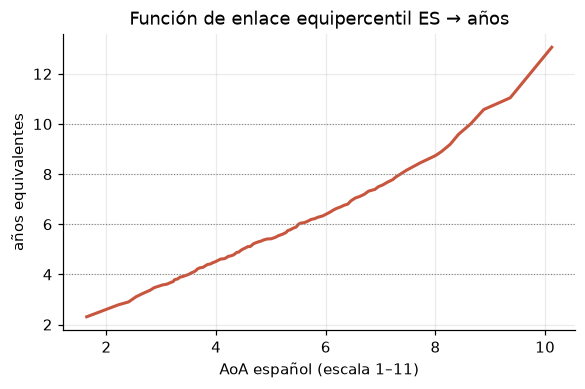

palabra   silabas  aoa  aoa_anios
     si        si 1.64       2.31
  comer    co-mer 1.70       2.36
  padre    pa-dre 1.72       2.38
     no        no 1.86       2.49
   agua     a-gua 1.94       2.56
   niña     ni-ña 1.96       2.57
     sí        sí 1.98       2.59
  madre    ma-dre 1.98       2.59
juguete ju-gue-te 2.16       2.74
   papa     pa-pa 2.20       2.77
  beber    be-ber 2.20       2.77
    uno      u-no 2.21       2.78


In [32]:
par = es.dropna(subset=["aoa_equivalente_en"])
q = np.linspace(0, 1, 101)
q_es, q_en = np.quantile(par["aoa"], q), np.quantile(par["aoa_equivalente_en"], q)
def escala_es_a_anios(x):
    return np.interp(x, q_es, q_en)
es["aoa_anios"] = escala_es_a_anios(es["aoa"])
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(q_es, q_en, color=C2, lw=2); ax.set_xlabel("AoA español (escala 1–11)"); ax.set_ylabel("años equivalentes")
for c in CORTES[1:-1]: ax.axhline(c, ls=":", c="gray", lw=.7)
ax.set_title("Función de enlace equipercentil ES → años"); guardar(fig, "12_enlace_equipercentil"); plt.show()
print(es.sort_values("aoa")[["palabra", "silabas", "aoa", "aoa_anios"]].head(12).round(2).to_string(index=False))

## 7. Aprendizaje no supervisado: familias de lecciones (K-Means)

**Objetivo:** dentro del vocabulario infantil (AoA < 10 años), descubrir **grupos de palabras con un perfil de decodificación parecido**. Así cada lección se arma con palabras de dificultad homogénea, por ejemplo cortas y frecuentes por un lado y largas con grupos consonánticos por otro. El clustering **no usa la AoA**; la AoA se usa solo para describir los grupos después.

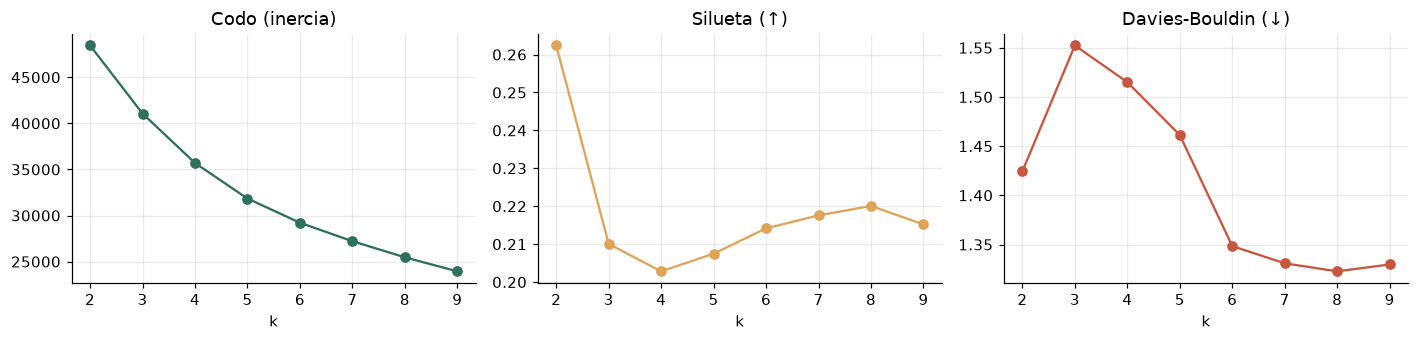

11565 palabras infantiles (10372 EN, 1193 ES)


,0,1,2,3,4,5,6,7
k,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000
silueta,0.262,0.210,0.203,0.207,0.214,0.218,0.220,0.215
davies_bouldin,1.424,1.552,1.515,1.461,1.348,1.331,1.323,1.330


In [33]:
VARS_K = ["zipf", "n_letras", "n_silabas", "grupo_cons_max", "vecinos_ort", "concrecion"]
infantil = pd.concat([
    en_full[(en_full["aoa"] < 10) & (en_full["pct_conocida"] >= .9)].assign(aoa_anios=lambda d: d["aoa"]),
    es.assign(aoa_anios=es["aoa_anios"])[es["aoa_anios"] < 10],
], ignore_index=True)
prep_k = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())])
Zk = prep_k.fit_transform(infantil[VARS_K])
ks = range(2, 10); sil, dbi, iner = [], [], []
for k in ks:
    km = KMeans(k, n_init=20, random_state=SEED).fit(Zk)
    iner.append(km.inertia_); sil.append(silhouette_score(Zk, km.labels_, sample_size=4000, random_state=SEED)); dbi.append(davies_bouldin_score(Zk, km.labels_))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, v, t, c in [(axes[0], iner, "Codo (inercia)", C1), (axes[1], sil, "Silueta (↑)", C3), (axes[2], dbi, "Davies-Bouldin (↓)", C2)]:
    ax.plot(ks, v, marker="o", c=c); ax.set_title(t); ax.set_xlabel("k")
plt.tight_layout(); guardar(fig, "13_kmeans_seleccion_k"); plt.show()
print(f"{len(infantil)} palabras infantiles ({(infantil.idioma=='en').sum()} EN, {(infantil.idioma=='es').sum()} ES)")
pd.DataFrame({"k": list(ks), "silueta": sil, "davies_bouldin": dbi}).round(3).T

### 7.1 Elección de *k* y comparación con otros algoritmos

Las métricas internas se complementan con **estabilidad**: se reentrena K-Means sobre 20 remuestreos *bootstrap* y se mide el acuerdo (*Adjusted Rand Index*, 1 = idéntico) con la solución sobre todos los datos. Un agrupamiento útil para armar lecciones no debe cambiar si cambian algunas palabras.

In [34]:
rng = np.random.default_rng(SEED); filas = []
for k in range(2, 9):
    base_k = KMeans(k, n_init=20, random_state=SEED).fit(Zk)
    ari = []
    for b in range(20):
        idx = rng.integers(0, len(Zk), len(Zk))
        m = KMeans(k, n_init=5, random_state=b).fit(Zk[idx])
        ari.append(adjusted_rand_score(base_k.labels_, m.predict(Zk)))
    filas.append({"k": k, "silueta": silhouette_score(Zk, base_k.labels_, sample_size=4000, random_state=SEED),
                  "Davies-Bouldin": davies_bouldin_score(Zk, base_k.labels_), "Calinski-Harabasz": calinski_harabasz_score(Zk, base_k.labels_),
                  "ARI bootstrap (media)": np.mean(ari), "ARI bootstrap (mín.)": np.min(ari), "familia más chica": np.bincount(base_k.labels_).min()})
estabilidad = pd.DataFrame(filas).set_index("k")
estabilidad.round(3)

,silueta,Davies-Bouldin,Calinski-Harabasz,ARI bootstrap (media),ARI bootstrap (mín.),familia más chica
k,,,,,,
2,0.262,1.424,4996.848,0.974,0.937,4679
3,0.210,1.552,3987.213,0.948,0.889,1682
4,0.203,1.515,3637.033,0.910,0.755,1523
5,0.207,1.461,3407.528,0.838,0.535,1402
6,0.214,1.348,3178.772,0.901,0.606,1312
7,0.218,1.331,2985.744,0.808,0.620,921
8,0.220,1.323,2847.623,0.782,0.544,768


In [35]:
# K-Means frente a Ward (jerárquico) y mezcla gaussiana, con el mismo k y la misma muestra
idx = np.random.default_rng(SEED).choice(len(Zk), 5000, replace=False); Zs = Zk[idx]
etq = {"K-Means": KMeans(4, n_init=20, random_state=SEED).fit_predict(Zs),
       "Jerárquico (Ward)": AgglomerativeClustering(4).fit_predict(Zs),
       "Mezcla gaussiana": GaussianMixture(4, n_init=5, random_state=SEED).fit_predict(Zs)}
comp_clu = pd.DataFrame({n: {"silueta": silhouette_score(Zs, e), "Davies-Bouldin": davies_bouldin_score(Zs, e),
                             "Calinski-Harabasz": calinski_harabasz_score(Zs, e), "ARI vs K-Means": adjusted_rand_score(etq["K-Means"], e),
                             "familia más chica": np.bincount(e).min()} for n, e in etq.items()}).T
comp_clu.round(3)

,silueta,Davies-Bouldin,Calinski-Harabasz,ARI vs K-Means,familia más chica
K-Means,0.203,1.503,1586.333,1.000,666.0
Jerárquico (Ward),0.162,1.743,1236.649,0.334,409.0
Mezcla gaussiana,0.035,3.564,754.134,0.189,795.0


In [36]:
K = 4
km = KMeans(K, n_init=50, random_state=SEED).fit(Zk)
infantil["familia"] = km.labels_
perfil = infantil.groupby("familia")[VARS_K + ["aoa_anios"]].mean()
perfil["n"] = infantil["familia"].value_counts().sort_index()
perfil["% español"] = infantil.groupby("familia")["idioma"].apply(lambda s: (s == "es").mean() * 100)
perfil["ejemplos"] = infantil.groupby("familia")["palabra"].apply(lambda s: ", ".join(s.sample(min(8, len(s)), random_state=SEED)))

# Nombre de negocio de cada familia, asignado de forma determinística según su centroide
nombres_fam, libres = {}, list(perfil.index)
for nombre, var, fn in [("Cortas con familia (rimas)", "vecinos_ort", "idxmax"),
                        ("Largas y abstractas", "n_letras", "idxmax"),
                        ("Con grupos consonánticos (tr, pl, str)", "grupo_cons_max", "idxmax")]:
    i = getattr(perfil.loc[libres, var], fn)(); nombres_fam[i] = nombre; libres.remove(i)
for i in libres: nombres_fam[i] = "Bisílabas frecuentes"
perfil.insert(0, "familia_nombre", perfil.index.map(nombres_fam))
infantil["familia_nombre"] = infantil["familia"].map(nombres_fam)
perfil.round(2)

,familia_nombre,zipf,n_letras,n_silabas,grupo_cons_max,vecinos_ort,concrecion,aoa_anios,n,% español,ejemplos
familia,,,,,,,,,,,
0,Cortas con familia (rimas),4.34,3.92,1.14,1.27,10.94,3.95,6.10,1523,10.64,"hump, dab, rash, real, move, chew, feel, poof"
1,Largas y abstractas,3.05,9.75,3.45,1.90,0.22,2.63,8.48,2358,5.94,"relation, distancia, interlocking, thankfulnes..."
2,"Con grupos consonánticos (tr, pl, str)",2.83,7.85,2.29,2.21,0.57,4.15,7.76,3534,6.23,"pastrami, scrapheap, wingless, unchanged, crum..."
3,Bisílabas frecuentes,3.97,5.76,1.93,1.43,1.96,3.54,7.01,4150,16.17,"caracol, tricky, barco, torre, cocoa, write, a..."


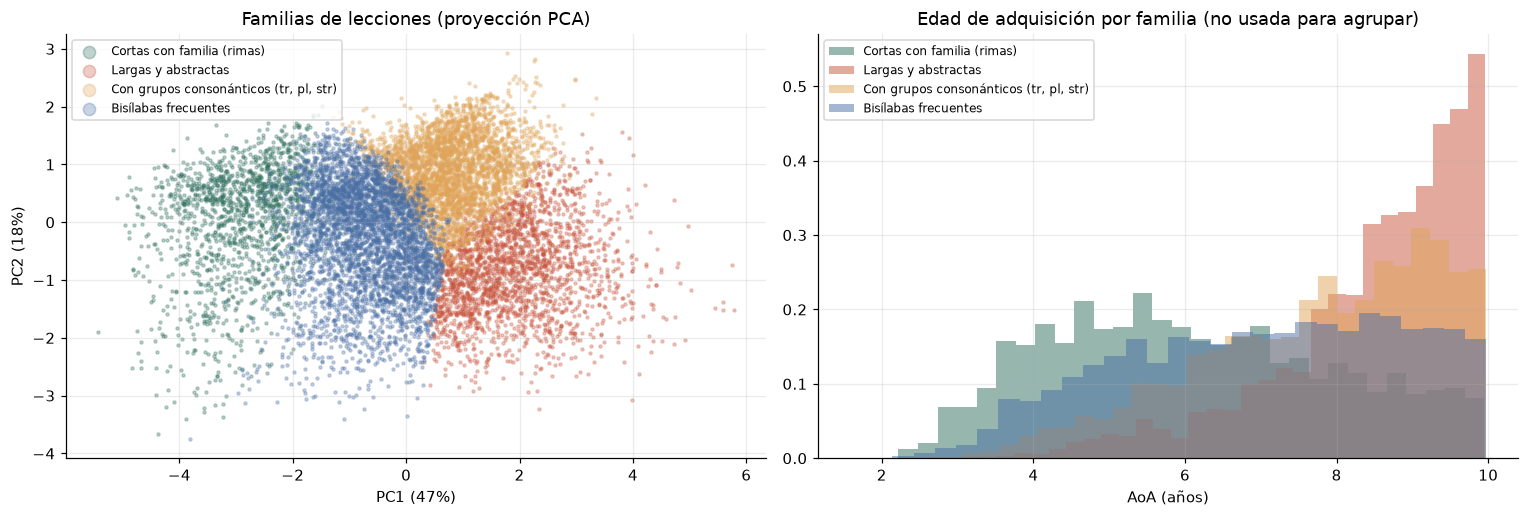

In [37]:
P = PCA(2, random_state=SEED).fit(Zk); Pz = P.transform(Zk)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for f, c in zip(range(K), [C1, C2, C3, C4]):
    m = infantil["familia"].values == f
    axes[0].scatter(Pz[m, 0], Pz[m, 1], s=4, alpha=.3, color=c, label=nombres_fam[f])
axes[0].set_xlabel(f"PC1 ({P.explained_variance_ratio_[0]:.0%})"); axes[0].set_ylabel(f"PC2 ({P.explained_variance_ratio_[1]:.0%})")
axes[0].legend(markerscale=4, fontsize=8); axes[0].set_title("Familias de lecciones (proyección PCA)")
for f, c in zip(range(K), [C1, C2, C3, C4]):
    axes[1].hist(infantil.loc[infantil.familia == f, "aoa_anios"], bins=30, alpha=.5, color=c, density=True, label=nombres_fam[f])
axes[1].set_xlabel("AoA (años)"); axes[1].set_title("Edad de adquisición por familia (no usada para agrupar)"); axes[1].legend(fontsize=8)
plt.tight_layout(); guardar(fig, "14_familias_lecciones"); plt.show()

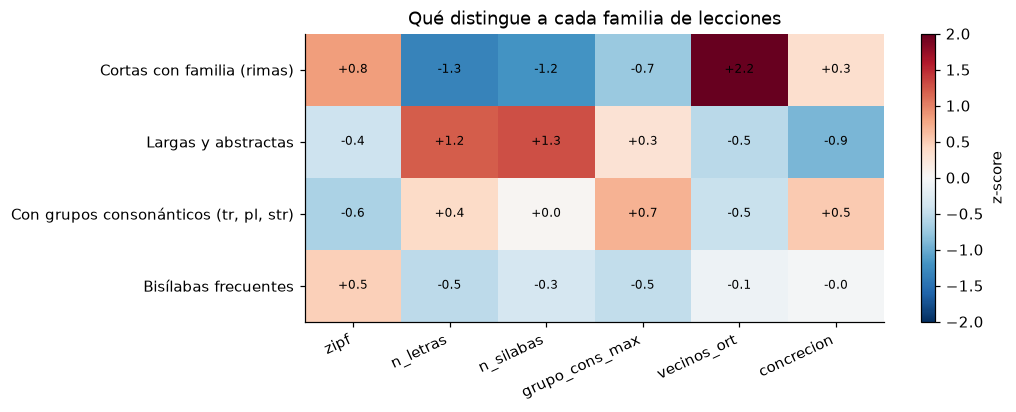

In [38]:
# Perfil de cada familia en desviaciones estándar respecto del vocabulario infantil completo
centros = pd.DataFrame(km.cluster_centers_, columns=VARS_K, index=[nombres_fam[i] for i in range(K)])
fig, ax = plt.subplots(figsize=(8.5, 3.4)); ax.grid(False)
im = ax.imshow(centros, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(VARS_K))); ax.set_xticklabels(VARS_K, rotation=25, ha="right"); ax.set_yticks(range(K)); ax.set_yticklabels(centros.index)
for i in range(K):
    for j in range(len(VARS_K)):
        ax.text(j, i, f"{centros.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="z-score"); ax.set_title("Qué distingue a cada familia de lecciones")
guardar(fig, "17_perfil_familias"); plt.show()

**Elección de k = 4**
* La **silueta** (0,20–0,26) y Davies-Bouldin no señalan un número claro de grupos: las palabras forman un **continuo**. Estas métricas, solas, no eligen k = 4 (la silueta prefiere k = 2 y Davies-Bouldin k = 8).
* **Estabilidad:** k = 4 mantiene un ARI medio de **0,91** (mínimo 0,76) en 20 remuestreos. k = 2 y 3 son más estables, pero entregan muy pocas familias para planificar lecciones; con k = 5 el ARI baja a 0,84 (mínimo 0,54).
* **Algoritmo:** con k = 4, **K-Means** supera a Ward y a la mezcla gaussiana en las tres métricas internas. El acuerdo entre algoritmos es bajo (ARI 0,33 y 0,19), otra señal de que las fronteras son difusas.
* **Decisión:** K-Means, k = 4, como **herramienta de organización pedagógica**, no como tipología natural de palabras.

**Patrones por familia** (mapa de calor): rimas = cortas y con muchos vecinos (+2,2 d.e.); largas y abstractas = más sílabas y baja concreción; grupos consonánticos = *tr, pl, str* y baja frecuencia; bisílabas frecuentes = frecuentes y sin grupos difíciles. La AoA media sube de 6,1 a 8,5 años entre familias sin haberse usado para agrupar, así que sugieren un **orden de lecciones**: rimas → bisílabas → grupos consonánticos → largas.

## 8. Sesgos, limitaciones y consideraciones éticas

In [39]:
d = pd.DataFrame({"palabra": pal_test.values, "real": y_test.values, "pred": pred_test[elegido],
                  "categoria": X_test["categoria"].values, "silabas": X_test["n_silabas"].clip(upper=4).values,
                  "sin_concrecion": X_test["concrecion"].isna().values})
filas = []
for col in ["categoria", "silabas", "sin_concrecion"]:
    for g, x in d.groupby(col):
        filas.append({"grupo": f"{col} = {g}", "n": len(x), "MAE": mean_absolute_error(x.real, x.pred),
                      "sesgo medio": (x.pred - x.real).mean(), "R²": r2_score(x.real, x.pred) if len(x) > 20 else np.nan})
equidad = pd.DataFrame(filas).round(3)
equidad

,grupo,n,MAE,sesgo medio,R²
0,categoria = adjetivo,1422,1.435,0.006,0.544
1,categoria = otra,196,1.382,-0.027,0.691
2,categoria = sustantivo,3452,1.563,-0.028,0.564
3,categoria = verbo,695,1.363,-0.210,0.630
4,silabas = 0,1,0.354,-0.354,NaN
5,silabas = 1,738,1.350,0.016,0.644
6,silabas = 2,2108,1.595,-0.040,0.455
7,silabas = 3,1615,1.539,-0.034,0.454
8,silabas = 4,1303,1.390,-0.086,0.419
9,sin_concrecion = False,4744,1.520,-0.049,0.523


### 8.1 Prueba de sesgo cultural: vocabulario chileno

Se mide cómo trata el modelo a palabras cotidianas en Chile frente a su equivalente de España, que es de donde vienen las normas y la frecuencia.

In [40]:
PARES_CL = [("guagua", "bebé", "baby"), ("palta", "aguacate", "avocado"), ("polera", "camiseta", "shirt"),
            ("frutilla", "fresa", "strawberry"), ("poroto", "judía", "bean"), ("choclo", "maíz", "corn"),
            ("zapallo", "calabaza", "pumpkin"), ("ampolleta", "bombilla", "bulb"), ("chancho", "cerdo", "pig"),
            ("pololo", "novio", "boyfriend")]
subtlex = lexico.cargar_subtlex_esp(); conc_en = lexico.cargar_concrecion_en()
kup = en_full.set_index("palabra")["aoa"]
def predecir_es(palabras, trad):
    d = pd.DataFrame({"palabra": palabras, "categoria": "sustantivo"})
    d["concrecion"] = pd.Series(trad).map(conc_en).values; d["aoa_equivalente_en"] = pd.Series(trad).map(kup).values
    d = d.join(lexico.rasgos_es(d["palabra"], subtlex)); d["opacidad"] = d["n_letras"] - d["n_fonemas"]
    d["pred_modelo_en"] = modelo_en.predict(d[NUM + CAT])
    x = es.dropna(subset=["aoa_equivalente_en"]); q = np.linspace(0, 1, 101)
    d["anios"] = np.interp(modelo_es.predict(d[num_es_final + CAT]), np.quantile(x["aoa"], q), np.quantile(x["aoa_equivalente_en"], q))
    return d
cl = predecir_es([a for a, _, _ in PARES_CL], [t for _, _, t in PARES_CL])
esp = predecir_es([b for _, b, _ in PARES_CL], [t for _, _, t in PARES_CL])
regional = pd.DataFrame({"Chile": cl.palabra, "España": esp.palabra, "zipf Chile": cl.zipf, "zipf España": esp.zipf,
                         "AoA pred. Chile": cl.anios, "AoA pred. España": esp.anios, "diferencia (años)": cl.anios - esp.anios,
                         "Chile en norma": cl.palabra.isin(es.palabra), "España en norma": esp.palabra.isin(es.palabra)})
print(f"En la norma española: {regional['Chile en norma'].sum()} de {len(regional)} palabras chilenas | "
      f"{regional['España en norma'].sum()} de {len(regional)} equivalentes de España")
print(f"Diferencia media de AoA predicha (Chile − España), mismo concepto: {regional['diferencia (años)'].mean():+.2f} años")
regional.round(2)

En la norma española: 0 de 10 palabras chilenas | 7 de 10 equivalentes de España
Diferencia media de AoA predicha (Chile − España), mismo concepto: +0.98 años


,Chile,España,zipf Chile,zipf España,AoA pred. Chile,AoA pred. España,diferencia (años),Chile en norma,España en norma
0,guagua,bebé,NaN,5.37,5.33,3.60,1.74,False,True
1,palta,aguacate,NaN,2.91,8.49,7.77,0.72,False,False
2,polera,camiseta,NaN,4.31,5.39,4.33,1.06,False,False
3,frutilla,fresa,3.07,3.55,5.14,4.63,0.51,False,True
4,poroto,judía,NaN,4.00,5.04,3.99,1.05,False,False
5,choclo,maíz,2.64,4.17,5.57,4.55,1.02,False,True
6,zapallo,calabaza,NaN,3.87,5.96,5.39,0.57,False,True
7,ampolleta,bombilla,2.28,3.28,6.78,6.30,0.48,False,True
8,chancho,cerdo,2.89,4.60,4.76,3.90,0.86,False,True
9,pololo,novio,NaN,5.12,7.58,5.81,1.77,False,True


**Evidencia de sesgo cultural:** ninguna de las 10 palabras chilenas está en la norma española (7 de sus 10 equivalentes de España sí) y el modelo les asigna en promedio **casi 1 año más** de AoA al mismo concepto (*guagua* 5,3 frente a *bebé* 3,6). Es una muestra pequeña, elegida a mano, y parte de las palabras de España estuvo en el entrenamiento, así que la cifra es indicativa. La causa es visible: 6 de las 10 no aparecen en los subtítulos de España. **Mitigación:** revisión por educadoras chilenas, tabla de equivalencias regionales y un corpus de frecuencia chileno o infantil antes de usarlo en aula.

**Sesgos de los datos**
* **Quién da la norma:** la AoA de Kuperman la estiman **adultos estadounidenses** (Amazon Mechanical Turk) recordando su infancia, no niños evaluados. La de Alonso viene de **adultos de España**. Pino apunta a niños chilenos y latinoamericanos, y el vocabulario regional (*palta* vs. *aguacate*, *polera*, *guagua*) no está representado. Riesgo: nivelar con una norma cultural ajena.
* **Corpus de frecuencia:** SUBTLEX son **subtítulos de películas y series**, que representan el habla adulta y no el habla dirigida a niños (CHILDES), ni los libros escolares. Las palabras típicas de la infancia (*tete*, *pipí*, *upa*) aparecen con frecuencia subestimada.
* **Concreción en español por traducción:** se usa la concreción del equivalente inglés. Las traducciones no siempre coinciden en sentido (*vino* vino/bebida).
* **Desempeño desigual:** la tabla de arriba muestra el error por categoría y por longitud. El error absoluto es mayor en **sustantivos** y en palabras de **2–3 sílabas**; los **verbos** tienen el mayor sesgo (se subestiman 0,21 años) y el R² cae a 0,27 en palabras **sin concreción**. Son las que conviene revisar a mano.

**Limitaciones del modelo**
* **Regresión hacia la media:** comprime los extremos. Las palabras más tempranas salen 1–2 años "más tarde" de lo real. Para el nivel 1 conviene complementar con listas de primeras palabras validadas (CDI / Wordbank).
* El modelo mide **dificultad léxica** (cuándo se conoce la palabra), no **dificultad de decodificación** (leerla). En español la decodificación es casi transparente, en inglés no; por eso se agregan sílabas, fonemas y opacidad al dataset de producto.
* En español el modelo se entrenó con 1.239 palabras (sustantivos y adjetivos). Con verbos y palabras regionales es menos confiable.

**Ética**
* El dataset es **a nivel de palabra**, no de persona: **no contiene datos personales** de niños. El riesgo de privacidad es bajo, a diferencia de un modelo sobre telemetría de usuarios.
* La nivelación afecta lo que ve un niño. El modelo **propone**, y una educadora **valida** antes de publicar, sobre todo los mayores errores, que el notebook lista.
* Hay que revisar el contenido semántico: una palabra puede ser "fácil" y aun así inapropiada (*beer*, *gun*). En la primera ejecución aparecieron palabras así porque la frecuencia viene de subtítulos de películas. Por eso el despliegue (§9) aplica un **filtro editorial** con listas de temas sensibles (groserías, violencia, alcohol y drogas, sexualidad). Es una primera barrera, no exhaustiva: la revisión humana sigue siendo obligatoria.
* **Licencias:** las normas usadas son de libre uso para investigación y docencia, y MultiPic es CC-BY. Un uso comercial requiere revisar cada licencia y citar a los autores.

**Privacidad y estándares aplicables**

| Aspecto | Situación en este proyecto | Si la app empieza a recoger datos de uso |
|---|---|---|
| Datos personales | Ninguno: normas agregadas por palabra | Aplican la **Ley 19.628** y su reforma, la **Ley 21.719** (vigencia desde el 1 de diciembre de 2026), que protege especialmente los datos de niños, niñas y adolescentes |
| Consentimiento | No requerido | Consentimiento de madre, padre o tutor; referencia internacional: GDPR art. 8 y COPPA |
| Minimización | Solo variables léxicas | Guardar aciertos por palabra con identificador seudónimo; sin audio ni nombre salvo necesidad justificada |
| Derechos | No aplica | Acceso, rectificación, supresión y portabilidad; plazo de retención definido |
| Decisiones automatizadas | El modelo propone y una persona valida | No bloquear contenido a un niño solo por una predicción |

## 9. Despliegue: dataset de vocabulario infantil para la app

Se generan tres archivos en `data/processed/` que la app puede consumir directamente:

| Archivo | Contenido |
|---|---|
| `vocabulario_infantil_es.csv` | Palabras en español con AoA (real o predicha), nivel de Pino, sílabas, fonemas, complejidad silábica, familia de lección y traducción |
| `vocabulario_infantil_en.csv` | Palabras en inglés (AoA < 10 años) con nivel, sílabas, fonemas CMU y familia de lección |
| `pares_imagen_es_en.csv` | Imágenes de MultiPic (500 en el archivo abierto) con su nombre en español y en inglés, el % de acuerdo y el nivel en cada idioma: el insumo para los ejercicios imagen–palabra |

In [41]:
mp = multipic[["codigo", "nombre_es", "acuerdo_es", "nombre_en_us", "acuerdo_en_us"]].dropna(subset=["nombre_es", "nombre_en_us"])
mp = mp[mp["nombre_es"].map(lexico.es_palabra_simple) & mp["nombre_en_us"].str.fullmatch(r"[a-z]+")]

# --- Filtro editorial: la AoA mide CUÁNDO se conoce una palabra, no si es APROPIADA para niños.
# Las frecuencias vienen de subtítulos de películas: aparecen groserías, violencia, alcohol, etc.
SENSIBLES_ES = set('''sexo sexual sexy muerte muerto muerta muertos matar mató maté mata matando asesino asesina asesinato sangre arma armas
pistola disparo disparar cerveza alcohol borracho borracha droga drogas infierno diablo demonio mierda puta puto joder coño carajo
idiota estúpido estúpida imbécil cárcel prisión guerra bomba cigarro cigarrillo fumar desnudo desnuda suicidio violación cadáver
odio maldito maldita culo tonto tonta pene vagina whisky vodka tequila ron licor'''.split())
SENSIBLES_EN = set('''sex sexy sexual damn damned hell murder murderer kill killer killed killing dead death die died gun guns shoot shot drug drugs
beer wine vodka whiskey whisky drunk bitch shit fuck ass asshole bastard crap stupid idiot hate blood bloody bomb war weapon knife
prison jail cigarette naked nude suicide rape slut whore penis vagina piss devil demon dumb hooker booze corpse'''.split())
# Segunda revisión (lista ampliada tras auditar el producto): insultos, armas, drogas, juego y sexualidad
SENSIBLES_ES |= set('''pedo teta tetas pezón condón tabaco bala granada ataúd esclavo pico vino'''.split())
SENSIBLES_EN |= set('''abuse ammo boob boobs bra breast bullet butt casino cigar cocktail coffin condom crotch dagger dope execution
fag fart gamble gambling grenade hump jerk joint kidnap liquor midget moron negro nigger nipple noose panties pistol
pussy retard revolver rifle saloon slaughter slave stab strangle sucker tobacco turd weed'''.split())

def sensible(w, lista):
    w = str(w).lower()
    return w in lista or any(w.startswith(r) for r in ("fuck", "shit", "bitch", "damn", "mierd", "put", "jod"))

# --- Español: normas reales + nombres de MultiPic sin norma (AoA predicha por el modelo ES)
subtlex = lexico.cargar_subtlex_esp(); conc_en = lexico.cargar_concrecion_en()
kup = en_full.set_index("palabra")["aoa"]
nuevas = mp[~mp["nombre_es"].isin(es["palabra"])].drop_duplicates("nombre_es")
es_new = pd.DataFrame({"palabra": nuevas["nombre_es"].values, "idioma": "es", "traduccion_en": nuevas["nombre_en_us"].values,
                       "categoria": "sustantivo"})
es_new["concrecion"] = es_new["traduccion_en"].map(conc_en).values
es_new["aoa_equivalente_en"] = es_new["traduccion_en"].map(kup).values
es_new = es_new.join(lexico.rasgos_es(es_new["palabra"], subtlex))
es_new["opacidad"] = es_new["n_letras"] - es_new["n_fonemas"]
es_new["pred_modelo_en"] = modelo_en.predict(es_new[NUM + CAT])
es_new["aoa_escala"] = modelo_es.predict(es_new[num_es_final + CAT]); es_new["fuente_aoa"] = "predicha (modelo ES)"
es_real = es.assign(aoa_escala=es["aoa"], fuente_aoa="norma Alonso et al. 2015")
voc_es = pd.concat([es_real, es_new], ignore_index=True)
voc_es["aoa_anios"] = escala_es_a_anios(voc_es["aoa_escala"])
voc_es["nivel_pino"] = pd.Series(nivel(voc_es["aoa_anios"])).map(dict(enumerate(NIVELES)))
voc_es["familia_leccion"] = pd.Series(km.predict(prep_k.transform(voc_es[VARS_K]))).map(nombres_fam)
voc_es["con_imagen_multipic"] = voc_es["palabra"].isin(mp["nombre_es"])
cols_es = ["palabra", "traduccion_en", "nivel_pino", "aoa_anios", "aoa_escala", "fuente_aoa", "silabas", "n_silabas", "fonemas",
           "complejidad_silabica", "n_letras", "zipf", "concrecion", "categoria", "familia_leccion", "con_imagen_multipic"]
voc_es = voc_es[voc_es["aoa_anios"] < 10]
excl_es = voc_es[voc_es["palabra"].map(lambda w: sensible(w, SENSIBLES_ES) and w not in ("puerta", "punto", "pupila"))]
voc_es = voc_es.drop(excl_es.index)[cols_es].sort_values(["aoa_anios", "palabra"]).round(3)
voc_es.to_csv(DATA_PROC / "vocabulario_infantil_es.csv", index=False)

# --- Inglés: normas reales < 10 años + nombres MultiPic sin norma (AoA predicha)
en_k = en_full[(en_full["aoa"] < 10) & (en_full["pct_conocida"] >= .9)].assign(fuente_aoa="norma Kuperman et al. 2012", aoa_anios=lambda d: d["aoa"])
en_mp = en_full[en_full["palabra"].isin(mp["nombre_en_us"]) & ~en_full["palabra"].isin(en_k["palabra"])].copy()
en_mp["aoa_anios"] = modelo_en.predict(en_mp[NUM + CAT]); en_mp["fuente_aoa"] = "predicha (modelo EN)"
voc_en = pd.concat([en_k, en_mp], ignore_index=True)
voc_en["nivel_pino"] = pd.Series(nivel(voc_en["aoa_anios"])).map(dict(enumerate(NIVELES)))
voc_en["familia_leccion"] = pd.Series(km.predict(prep_k.transform(voc_en[VARS_K]))).map(nombres_fam)
voc_en["con_imagen_multipic"] = voc_en["palabra"].isin(mp["nombre_en_us"])
tr = mp.drop_duplicates("nombre_en_us").set_index("nombre_en_us")["nombre_es"]
voc_en["traduccion_es"] = voc_en["palabra"].map(tr)
voc_en = voc_en[voc_en["aoa_anios"] < 10]
excl_en = voc_en[voc_en["palabra"].map(lambda w: sensible(w, SENSIBLES_EN))]
voc_en = voc_en.drop(excl_en.index)
voc_en = voc_en[["palabra", "traduccion_es", "nivel_pino", "aoa_anios", "fuente_aoa", "n_silabas", "fonemas",
                                           "n_letras", "opacidad", "zipf", "concrecion", "categoria", "familia_leccion", "con_imagen_multipic"]]
voc_en = voc_en.sort_values(["aoa_anios", "palabra"]).round(3)
voc_en.to_csv(DATA_PROC / "vocabulario_infantil_en.csv", index=False)

# --- Pares imagen–palabra
_todo_es = pd.concat([es_real, es_new]).drop_duplicates("palabra")
aoa_es_map = pd.Series(escala_es_a_anios(_todo_es["aoa_escala"]), index=_todo_es["palabra"].values)
aoa_en_map = pd.concat([en_k, en_mp]).drop_duplicates("palabra").set_index("palabra")["aoa_anios"]
pares = mp[~mp["nombre_es"].map(lambda w: sensible(w, SENSIBLES_ES) and w not in ("puerta", "punto", "pupila"))
            & ~mp["nombre_en_us"].map(lambda w: sensible(w, SENSIBLES_EN))].copy()
pares["aoa_es_anios"] = pares["nombre_es"].map(aoa_es_map).round(2); pares["aoa_en_anios"] = pares["nombre_en_us"].map(aoa_en_map).round(2)
pares["nivel_es"] = pd.Series(nivel(pares["aoa_es_anios"].fillna(99))).map(dict(enumerate(NIVELES))).values
pares["nivel_en"] = pd.Series(nivel(pares["aoa_en_anios"].fillna(99))).map(dict(enumerate(NIVELES))).values
pares["silabas_es"] = [ "-".join(lexico.texto_es.separar_silabas(w)) for w in pares["nombre_es"]]
pares = pares.sort_values("aoa_es_anios")
pares.to_csv(DATA_PROC / "pares_imagen_es_en.csv", index=False)

resumen_prod = pd.DataFrame({
    "español": voc_es["nivel_pino"].value_counts(), "inglés": voc_en["nivel_pino"].value_counts(),
    "pares imagen (nivel ES)": pares["nivel_es"].value_counts()}).reindex(NIVELES).fillna(0).astype(int)
resumen_prod.loc["TOTAL"] = resumen_prod.sum()
print(f"Excluidas por el filtro editorial: {len(excl_es)} ES ({', '.join(excl_es['palabra'].head(12))}) | "
      f"{len(excl_en)} EN ({', '.join(excl_en['palabra'].head(12))})")
resumen_prod

Excluidas por el filtro editorial: 35 ES (bala, pedo, pene, cárcel, teta, matar, borracho, tonto, estúpido, vino, pistola, muerto) | 95 EN (abuse, ammo, ass, asshole, beer, blood, bloody, bomb, boob, bra, breast, bullet)


,español,inglés,pares imagen (nivel ES)
1 · Primeras palabras,193,316,83
2 · Preescolar,622,1641,230
3 · Lectura inicial,374,3182,135
4 · Lector en desarrollo,112,5147,17
Fuera de foco,0,0,0
TOTAL,1301,10286,465


In [42]:
# Para lecciones con imagen: palabras concretas (concreción ≥ 4) ordenadas por frecuencia dentro de cada nivel
print("Español — palabras concretas sugeridas por nivel (sílabas):")
for nv in NIVELES[:4]:
    x = voc_es[(voc_es.nivel_pino == nv) & (voc_es.concrecion >= 4) & (voc_es.categoria == "sustantivo")].sort_values("zipf", ascending=False).head(10)
    print(f"  {nv:<26}", ", ".join(f"{p} ({s})" for p, s in zip(x.palabra, x.silabas)))
print("\nInglés — palabras concretas sugeridas por nivel:")
for nv in NIVELES[:4]:
    x = voc_en[(voc_en.nivel_pino == nv) & (voc_en.concrecion >= 4) & (voc_en.categoria == "sustantivo")].sort_values("zipf", ascending=False).head(12)
    print(f"  {nv:<26}", ", ".join(x.palabra))

Español — palabras concretas sugeridas por nivel (sílabas):
  1 · Primeras palabras      casa (ca-sa), noche (no-che), padre (pa-dre), hijo (hi-jo), madre (ma-dre), familia (fa-mi-lia), hermano (her-ma-no), cabeza (ca-be-za), puerta (puer-ta), niño (ni-ño)
  2 · Preescolar             hombre (hom-bre), gente (gen-te), dinero (di-ne-ro), mundo (mun-do), mujer (mu-jer), esposa (es-po-sa), persona (per-so-na), camino (ca-mi-no), hija (hi-ja), ciudad (ciu-dad)
  3 · Lectura inicial        oficina (o-fi-ci-na), país (pa-ís), hospital (hos-pi-tal), novia (no-via), cerebro (ce-re-bro), carta (car-ta), banco (ban-co), norte (nor-te), laboratorio (la-bo-ra-to-rio), té (té)
  4 · Lector en desarrollo   presidente (pre-si-den-te), testigo (tes-ti-go), frontera (fron-te-ra), emperador (em-pe-ra-dor), masa (ma-sa), acero (a-ce-ro), grasa (gra-sa), plano (pla-no), diamante (dia-man-te), multitud (mul-ti-tud)

Inglés — palabras concretas sugeridas por nivel:
  1 · Primeras palabras      man, people, 

## 10. Evaluación frente a los KPIs

In [43]:
r = test_tab.loc[elegido]
KPIS = [("MAE test EN (años)", "≤", 1.6, r["MAE test"]), ("R² test EN", "≥", .55, r["R²"]), ("Spearman test EN", "≥", .75, r["Spearman"]),
        ("Brecha MAE train–validación (años)", "≤", .30, rep.loc[elegido, "brecha"]), ("Nivel correcto ± 1", "≥", .90, r["nivel ±1"]),
        ("Error grave", "≤", .02, r["error grave"]), ("Spearman ES, mejor estrategia", "≥", .60, tabla_es.loc[mejor_es, "Spearman"]),
        ("Spearman ES, zero-shot", "≥", .60, rho_A), ("Palabras niveladas ES", "≥", 1000, len(voc_es)), ("Palabras niveladas EN", "≥", 1000, len(voc_en))]
tabla_kpi = pd.DataFrame([{"KPI": n, "meta": f"{s} {m:g}", "resultado": round(float(x), 4),
                           "cumple": "sí" if (x <= m if s == "≤" else x >= m) else "NO"} for n, s, m, x in KPIS]).set_index("KPI")
tabla_kpi

,meta,resultado,cumple
KPI,,,
MAE test EN (años),≤ 1.6,1.5014,sí
R² test EN,≥ 0.55,0.5805,sí
Spearman test EN,≥ 0.75,0.7371,NO
Brecha MAE train–validación (años),≤ 0.3,0.0624,sí
Nivel correcto ± 1,≥ 0.9,0.9435,sí
Error grave,≤ 0.02,0.0005,sí
"Spearman ES, mejor estrategia",≥ 0.6,0.7089,sí
"Spearman ES, zero-shot",≥ 0.6,0.5317,NO
Palabras niveladas ES,≥ 1000,1301.0000,sí


Se cumplen **8 de 10** KPIs. No se cumplen el Spearman en test inglés (0,737 frente a 0,75) ni la transferencia *zero-shot* al español (0,53 frente a 0,60). El primero queda cerca y no impide ubicar la palabra en su nivel; el segundo se resuelve con la estrategia combinada (0,71).

In [44]:
joblib.dump(finales[elegido], MODELS / "modelo_aoa_en.joblib")
joblib.dump({"modelo": modelo_es, "variables": num_es_final + CAT, "q_es": q_es, "q_en": q_en}, MODELS / "modelo_aoa_es.joblib")
joblib.dump({"kmeans": km, "prep": prep_k, "variables": VARS_K, "nombres": nombres_fam}, MODELS / "kmeans_familias.joblib")
r = test_tab.loc[elegido]
metricas = {
    "modelo_en_elegido": elegido,
    "regla_seleccion": "menor MAE en CV repetida 5x3; entre los modelos a menos de 0,02 años del mejor y con brecha ≤ 0,30 años se elige el más simple",
    "hiperparametros": {n: {k.replace("modelo__", ""): (float(v) if isinstance(v, (float, np.floating)) else v) for k, v in s.best_params_.items()} for n, s in busquedas.items()},
    "cv_repetida_en": rep.round(4).to_dict(orient="index"),
    "test_en": test_tab.drop(columns="IC95% MAE").round(4).to_dict(orient="index"),
    "espanol": {"spearman_zero_shot": round(float(rho_A), 4), "mejor_estrategia": mejor_es, "hiperparametros": hp_es,
                "optimizacion": opt_es.reset_index().round(4).to_dict(orient="records"),
                "tabla": tabla_es.round(4).to_dict(orient="index")},
    "familias_lecciones": {v: int((infantil["familia_nombre"] == v).sum()) for v in nombres_fam.values()},
    "producto": {"palabras_es": int(len(voc_es)), "palabras_en": int(len(voc_en)), "pares_imagen": int(len(pares))},
    "kpis": tabla_kpi.reset_index().to_dict(orient="records"),
    "estabilidad_kmeans": estabilidad.round(4).to_dict(orient="index"),
    "version_sklearn": sklearn.__version__, "seed": SEED,
}
with open(MODELS / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2, ensure_ascii=False, default=str)

print("=" * 72); print(f"RESUMEN — modelo inglés elegido: {elegido}"); print("=" * 72)
print(f"Test EN: MAE = {r['MAE test']:.3f} años {r['IC95% MAE']} | R² = {r['R²']:.3f} | Spearman = {r['Spearman']:.3f}")
print(f"Niveles: exacto {r['nivel exacto']:.1%} | ±1 nivel {r['nivel ±1']:.1%} | error grave {r['error grave']:.2%}")
print(f"CV repetida: MAE {rep.loc[elegido, 'MAE media']:.3f} ± {rep.loc[elegido, 'MAE d.e.']:.3f} | brecha {rep.loc[elegido, 'brecha']:.3f}")
print(f"Español: zero-shot ρ = {rho_A:.3f} | mejor: {mejor_es} (MAE {tabla_es.loc[mejor_es, 'MAE']:.3f}, ρ {tabla_es.loc[mejor_es, 'Spearman']:.3f})")
print(f"Producto: {len(voc_es)} palabras ES, {len(voc_en)} palabras EN, {len(pares)} pares imagen–palabra")

RESUMEN — modelo inglés elegido: Gradient Boosting
Test EN: MAE = 1.501 años [1.472, 1.531] | R² = 0.581 | Spearman = 0.737
Niveles: exacto 67.4% | ±1 nivel 94.3% | error grave 0.05%
CV repetida: MAE 1.482 ± 0.018 | brecha 0.062
Español: zero-shot ρ = 0.532 | mejor: C · Stacking + transferencia (MAE 0.953, ρ 0.709)
Producto: 1301 palabras ES, 10286 palabras EN, 465 pares imagen–palabra


## 11. Conclusiones, limitaciones y recomendaciones

**Conclusiones**
1. **Se puede apoyar la nivelación:** Gradient Boosting estima la AoA con MAE 1,50 años en palabras nuevas y ubica el 94 % en su nivel ±1 (81,6 % sin modelo), con 0,05 % de errores graves. En palabras infantiles logra 87 % a ±1 y casi no asigna el nivel 1; ver `analisis_por_nivel.ipynb`, que prueba cortes calibrados.
2. **Solución elegida: Gradient Boosting**, equivalente al Stacking en error, 24 veces más rápido de ajustar y 87 veces más liviano.
3. **Los ensambles aportan** frente a un árbol (hasta 26 % menos error) y a Ridge (6 %); los heterogéneos no justifican su costo.
4. **El inglés ayuda al español:** la transferencia sube Spearman de 0,55 a 0,71.
5. **El no supervisado organiza las lecciones** en cuatro familias estables, útiles para secuenciar, aunque sin fronteras naturales.

**Limitaciones:** normas de adultos de EE. UU. y España; frecuencia de subtítulos; regresión hacia la media (nivel 1 sub-representado); solo 1.239 palabras en español; sesgo contra vocabulario chileno; se mide cuándo se *conoce* una palabra, no cuán difícil es leerla.

**Recomendaciones para el negocio**
1. Usar el dataset nivelado como punto de partida y que las educadoras **validen** en vez de nivelar desde cero.
2. Priorizar la revisión en nivel 1, sustantivos de 2–3 sílabas, palabras sin concreción y vocabulario chileno.
3. Integrar el modelo al backend y usar la AoA como dificultad inicial de la repetición espaciada.
4. Sumar Wordbank/CHILDES y una lista chilena validada; re-entrenar con aciertos reales, con consentimiento y datos seudonimizados.
5. Monitorear: porcentaje de niveles corregidos por educadoras (reentrenar si supera 20 %) y error en palabras nuevas.